In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors, Dates
using CSV
using DataFrames

In [2]:
# Features: windspeed_10m, windspeed_100m, windgusts_10m
# One-day batches, preserving feature transformations and feature weights

using CSV, DataFrames, Dates, Statistics, Random, LinearAlgebra, Colors

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load training datasets
data1 = CSV.read("Location1.csv", DataFrame)
data2 = CSV.read("Location2.csv", DataFrame)
data3 = CSV.read("Location3.csv", DataFrame)

data1.Time = DateTime.(data1.Time)
data2.Time = DateTime.(data2.Time)
data3.Time = DateTime.(data3.Time)

# Combine and sort chronologically
data = vcat(data1, data2, data3)
sort!(data, :Time)

n = nrow(data)

# Extract target and features
t = Float64.(data.Power)

wind10_raw   = Float64.(data.windspeed_10m)
wind100_raw  = Float64.(data.windspeed_100m)
windgust_raw = Float64.(data.windgusts_10m)

time = data.Time

# Normalize features
x       = wind10_raw ./ 10.0
z       = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

# Time features (retained for compatibility; not currently used in prediction)
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# Group row indices into daily batches
day_keys = Date.(time)
unique_days = unique(day_keys)

daily_batches = [
    findall(day_keys .== day)
    for day in unique_days
]

println("Number of daily batches: ", length(daily_batches))
println("First batch size: ", length(daily_batches[1]), " rows")

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

# Build RBF matrices
Φ_10   = zeros(n, num_centers)
Φ_100  = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ_10[i, j]   = φ(x[i], j)
        Φ_100[i, j]  = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

# RBF weights
w_10   = rand(num_centers)
w_100  = rand(num_centers)
w_gust = rand(num_centers)

# Feature weights
β_100 = rand()
β_windgust = rand()

# Stochastic gradient descent using one-day batches
for iteration in 1:iter_max

    # Select one day, then one observation from that day
    batch_index = rand(1:length(daily_batches))
    batch = daily_batches[batch_index]
    i = rand(batch)

    ϕ10_i   = Φ_10[i, :]
    ϕ100_i  = Φ_100[i, :]
    ϕgust_i = Φ_gust[i, :]

    # RBF contribution from each feature
    f_10   = dot(ϕ10_i, w_10)
    f_100  = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust

    error = y_hat - t[i]

    # Bias update
    w_0 -= α * error

    # RBF weights: windspeed_10m
    for j in 1:num_centers
        w_10[j] -= α * error * ϕ10_i[j]
    end

    # RBF weights: windspeed_100m
    for j in 1:num_centers
        w_100[j] -= α * error * β_100 * ϕ100_i[j]
    end

    # RBF weights: windgusts_10m
    for j in 1:num_centers
        w_gust[j] -= α * error * β_windgust * ϕgust_i[j]
    end

    # Feature-weight updates
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust

    # Regularization
    if reg_type == "l2"

        w_10   .-= α * λ .* w_10
        w_100  .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100     -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

    elseif reg_type == "l1"

        w_10   .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100  .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)
    end
end

# Prediction function
function w̅(x_value, z_value, windgust_value)

    f_10 = sum(w_10[j] * φ(x_value, j)
               for j in 1:num_centers)

    f_100 = sum(w_100[j] * φ(z_value, j)
                for j in 1:num_centers)

    f_gust = sum(w_gust[j] * φ(windgust_value, j)
                 for j in 1:num_centers)

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust
end

# Predict across the complete dataset
prediction = w_0 .+
             Φ_10 * w_10 .+
             β_100 .* (Φ_100 * w_100) .+
             β_windgust .* (Φ_gust * w_gust)

# Model performance
errors = prediction .- t

RMSE = sqrt(mean(errors .^ 2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("=======================================")



Number of daily batches: 1825
First batch size: 72 rows

========== MODEL PERFORMANCE ==========
RMSE = 0.2169192867197395
MAE  = 0.17011652801179158
β_100 = -0.3449097535768147
β_windgust = -0.20818688842581243


In [ ]:
# Features: windspeed_10m, windspeed_100m, windgusts_10m
# One-day batches, training on adjacent hourly observations
# Preserves Gaussian RBF transformations and feature weights

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load training datasets
data1 = CSV.read("Location1.csv", DataFrame)
data2 = CSV.read("Location2.csv", DataFrame)
data3 = CSV.read("Location3.csv", DataFrame)

data1.Time = DateTime.(data1.Time)
data2.Time = DateTime.(data2.Time)
data3.Time = DateTime.(data3.Time)

# Combine and sort chronologically
data = vcat(data1, data2, data3)
sort!(data, :Time)

n = nrow(data)

# Extract target and features
t = Float64.(data.Power)

wind10_raw   = Float64.(data.windspeed_10m)
wind100_raw  = Float64.(data.windspeed_100m)
windgust_raw = Float64.(data.windgusts_10m)

time = data.Time

# Normalize features
x        = wind10_raw ./ 10.0
z        = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

# Time features (retained for compatibility)
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# --------------------------------------------------
# Build daily batches of adjacent hourly pairs
# --------------------------------------------------

day_keys = Date.(time)
unique_days = unique(day_keys)

daily_batches = Vector{Vector{Tuple{Int, Int}}}()

for day in unique_days

    # All rows belonging to this day
    indices = findall(day_keys .== day)

    # Keep pairs only if observations are exactly one hour apart
    pairs_today = Tuple{Int, Int}[]

    for k in 1:(length(indices) - 1)
        i = indices[k]
        j = indices[k + 1]

        if time[j] - time[i] == Hour(1)
            push!(pairs_today, (i, j))
        end
    end

    # Exclude days without valid adjacent hourly pairs
    if !isempty(pairs_today)
        push!(daily_batches, pairs_today)
    end
end

if isempty(daily_batches)
    error("No adjacent hourly pairs found. Check timestamps and duplicate observations.")
end

total_pairs = sum(length(batch) for batch in daily_batches)

println("Number of daily batches: ", length(daily_batches))
println("Number of adjacent hourly pairs: ", total_pairs)
println("First nonempty batch size: ", length(daily_batches[1]), " pairs")

# --------------------------------------------------
# Hyperparameters
# --------------------------------------------------

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

# --------------------------------------------------
# Build RBF matrices
# --------------------------------------------------

Φ_10   = zeros(n, num_centers)
Φ_100  = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ_10[i, j]   = φ(x[i], j)
        Φ_100[i, j]  = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)
    end
end

# --------------------------------------------------
# Initialize parameters
# --------------------------------------------------

Random.seed!(128)

w_0 = rand()

w_10   = rand(num_centers)
w_100  = rand(num_centers)
w_gust = rand(num_centers)

β_100 = rand()
β_windgust = rand()

# --------------------------------------------------
# SGD using adjacent hourly pairs
# --------------------------------------------------

for iteration in 1:iter_max

    # Randomly select a day and a consecutive hourly pair
    batch_index = rand(1:length(daily_batches))
    batch = daily_batches[batch_index]

    pair_index = rand(1:length(batch))
    i, j = batch[pair_index]

    # Accumulate gradients from both adjacent observations
    grad_w0 = 0.0

    grad_w10   = zeros(num_centers)
    grad_w100  = zeros(num_centers)
    grad_wgust = zeros(num_centers)

    grad_β100 = 0.0
    grad_βgust = 0.0

    for k in (i, j)

        ϕ10_i   = @view Φ_10[k, :]
        ϕ100_i  = @view Φ_100[k, :]
        ϕgust_i = @view Φ_gust[k, :]

        f_10   = dot(ϕ10_i, w_10)
        f_100  = dot(ϕ100_i, w_100)
        f_gust = dot(ϕgust_i, w_gust)

        y_hat = w_0 +
                f_10 +
                β_100 * f_100 +
                β_windgust * f_gust

        error = y_hat - t[k]

        # Accumulate gradients
        grad_w0 += error

        grad_w10   .+= error .* ϕ10_i
        grad_w100  .+= error * β_100 .* ϕ100_i
        grad_wgust .+= error * β_windgust .* ϕgust_i

        grad_β100  += error * f_100
        grad_βgust += error * f_gust
    end

    # Average gradients across the adjacent pair
    grad_w0 /= 2

    grad_w10   ./= 2
    grad_w100  ./= 2
    grad_wgust ./= 2

    grad_β100  /= 2
    grad_βgust /= 2

    # Update bias
    w_0 -= α * grad_w0

    # Update RBF weights
    w_10   .-= α .* grad_w10
    w_100  .-= α .* grad_w100
    w_gust .-= α .* grad_wgust

    # Update feature weights
    β_100     -= α * grad_β100
    β_windgust -= α * grad_βgust

    # Regularization
    if reg_type == "l2"

        w_10   .-= α * λ .* w_10
        w_100  .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100     -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

    elseif reg_type == "l1"

        w_10 .= sign.(w_10) .*
                max.(0, abs.(w_10) .- α * λ)

        w_100 .= sign.(w_100) .*
                 max.(0, abs.(w_100) .- α * λ)

        w_gust .= sign.(w_gust) .*
                  max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) *
                max(0, abs(β_100) - α * λ)

        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)
    end
end

# --------------------------------------------------
# Prediction function
# --------------------------------------------------

function w̅(x_value, z_value, windgust_value)

    f_10 = sum(w_10[j] * φ(x_value, j)
               for j in 1:num_centers)

    f_100 = sum(w_100[j] * φ(z_value, j)
                for j in 1:num_centers)

    f_gust = sum(w_gust[j] * φ(windgust_value, j)
                 for j in 1:num_centers)

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust
end

# --------------------------------------------------
# Predict across the complete dataset
# --------------------------------------------------

prediction = w_0 .+
             Φ_10 * w_10 .+
             β_100 .* (Φ_100 * w_100) .+
             β_windgust .* (Φ_gust * w_gust)

# --------------------------------------------------
# Model performance
# --------------------------------------------------

errors = prediction .- t

RMSE = sqrt(mean(errors .^ 2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("=======================================")

Number of daily batches: 1825
Number of adjacent hourly pairs: 41975
First nonempty batch size: 23 pairs

========== MODEL PERFORMANCE ==========
RMSE = 0.2314283098012177
MAE  = 0.18105991366758764
β_100 = -0.3748227547212366
β_windgust = -0.16294733148622045


In [ ]:
#Time correlated algorithm

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)

data.Time = DateTime.(data.Time)

# Sort observations chronologically
sort!(data, :Time)

n_original = nrow(data)

# Lag 1 = power one hour earlier
# Lag 2 = power two hours earlier
data.Power_lag1 = Vector{Union{Missing, Float64}}(missing, n_original)
data.Power_lag2 = Vector{Union{Missing, Float64}}(missing, n_original)

for k in 2:n_original
    if data.Time[k] - data.Time[k-1] == Hour(1)
        data.Power_lag1[k] = Float64(data.Power[k-1])
    end
end

for k in 3:n_original
    if data.Time[k] - data.Time[k-1] == Hour(1) &&
       data.Time[k-1] - data.Time[k-2] == Hour(1)
        data.Power_lag2[k] = Float64(data.Power[k-2])
    end
end

# Remove rows without both lagged observations
data = dropmissing(data, [:Power_lag1, :Power_lag2])

n = nrow(data)

t = Float64.(data.Power)

wind10_raw = Float64.(data.windspeed_10m)
wind100_raw = Float64.(data.windspeed_100m)
windgust_raw = Float64.(data.windgusts_10m)

time = data.Time

# Normalize wind features
x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

# Time-of-day features (retained, but not used in the model)
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# Standardize lagged power features
lag1_raw = Float64.(data.Power_lag1)
lag2_raw = Float64.(data.Power_lag2)

lag1_mean = mean(lag1_raw)
lag2_mean = mean(lag2_raw)

lag1_std = std(lag1_raw)
lag2_std = std(lag2_raw)

lag1_std = lag1_std > 0 ? lag1_std : 1.0
lag2_std = lag2_std > 0 ? lag2_std : 1.0

lag1 = (lag1_raw .- lag1_mean) ./ lag1_std
lag2 = (lag2_raw .- lag2_mean) ./ lag2_std


# Model parameters

α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end


# Construct RBF matrices

Φ_10 = zeros(n, num_centers)
Φ_100 = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ_10[i, j] = φ(x[i], j)
        Φ_100[i, j] = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)
    end
end

# Initialize model weights

Random.seed!(128)

w_0 = rand()

w_10 = rand(num_centers)
w_100 = rand(num_centers)
w_gust = rand(num_centers)

# Feature weights
β_100 = rand()
β_windgust = rand()

# Autoregressive weights
β_lag1 = 0.0
β_lag2 = 0.0

# Stochastic gradient descent

for iteration in 1:iter_max

    i = rand(1:n)

    ϕ10_i = Φ_10[i, :]
    ϕ100_i = Φ_100[i, :]
    ϕgust_i = Φ_gust[i, :]

    # RBF contribution from each wind feature
    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    # Autoregressive contribution
    f_lag1 = β_lag1 * lag1[i]
    f_lag2 = β_lag2 * lag2[i]

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust +
            f_lag1 +
            f_lag2

    error = y_hat - t[i]

    # Update bias
    w_0 -= α * error

    # Update RBF weights for windspeed_10m
    for j in 1:num_centers
        w_10[j] -= α * error * ϕ10_i[j]
    end

    # Update RBF weights for windspeed_100m
    for j in 1:num_centers
        w_100[j] -= α * error * β_100 * ϕ100_i[j]
    end

    # Update RBF weights for windgusts_10m
    for j in 1:num_centers
        w_gust[j] -= α * error * β_windgust * ϕgust_i[j]
    end

    # Update feature weights
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust

    # Update autoregressive weights
    β_lag1 -= α * error * lag1[i]
    β_lag2 -= α * error * lag2[i]

    # Regularization
    if reg_type == "l2"

        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

        β_lag1 -= α * λ * β_lag1
        β_lag2 -= α * λ * β_lag2

    elseif reg_type == "l1"

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)

        β_lag1 = sign(β_lag1) * max(0, abs(β_lag1) - α * λ)
        β_lag2 = sign(β_lag2) * max(0, abs(β_lag2) - α * λ)
    end
end

# Prediction function

function predict_power(x_value, z_value, gust_value, lag1_value, lag2_value)

    f_10 = sum(w_10[j] * φ(x_value, j)
               for j in 1:num_centers)

    f_100 = sum(w_100[j] * φ(z_value, j)
                for j in 1:num_centers)

    f_gust = sum(w_gust[j] * φ(gust_value, j)
                 for j in 1:num_centers)

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust +
           β_lag1 * lag1_value +
           β_lag2 * lag2_value
end

prediction = [
    predict_power(x[i], z[i], windgust[i], lag1[i], lag2[i])
    for i in 1:n
]

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("β_lag1 = ", β_lag1)
println("β_lag2 = ", β_lag2)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.03357964083934352
MAE  = 0.025116825744682658
β_100 = 0.016664042241888347
β_windgust = 0.05342073854050098
β_lag1 = 0.30688415324135676
β_lag2 = -0.03127652540581208


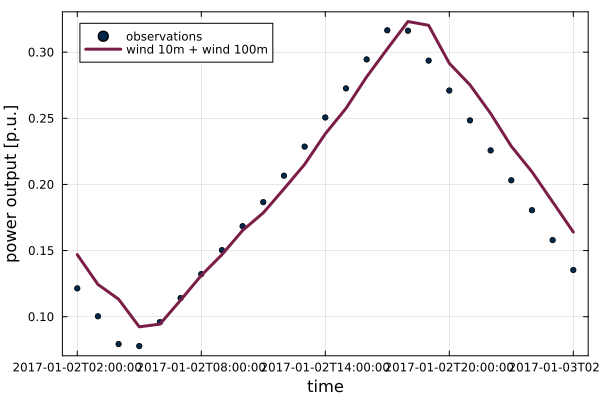

In [13]:
one_day = time .<= (time[1] + Day(1))
time_1day = time[one_day]
t_1day = t[one_day]
prediction_1day = prediction[one_day]

plo = scatter(time_1day,t_1day,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_1day,prediction_1day,lw=3,c=purple,label="wind 10m + wind 100m")

display(plo)


========== DAILY FORECAST PERFORMANCE ==========
Predicted hours = 43776
RMSE = 0.2050062733120432
MAE  = 0.15825372232245477
β_100 = 0.016664042241888347
β_windgust = 0.05342073854050098
β_lag1 = 0.30688415324135676
β_lag2 = -0.03127652540581208


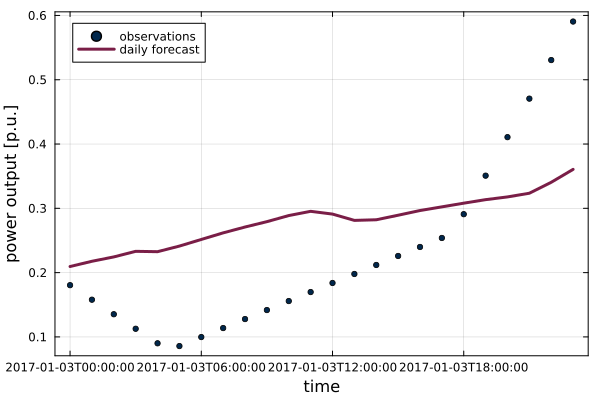

In [ ]:
# Time-correlated daily forecasting algorithm

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

n_original = nrow(data)

# Create hourly lagged power features
data.Power_lag1 = Union{Missing, Float64}[missing for _ in 1:n_original]
data.Power_lag2 = Union{Missing, Float64}[missing for _ in 1:n_original]

for k in 2:n_original
    if data.Time[k] - data.Time[k-1] == Hour(1)
        data.Power_lag1[k] = Float64(data.Power[k-1])
    end
end

for k in 3:n_original
    if data.Time[k] - data.Time[k-1] == Hour(1) &&
       data.Time[k-1] - data.Time[k-2] == Hour(1)

        data.Power_lag2[k] = Float64(data.Power[k-2])
    end
end

# Remove rows without both lagged observations
data = dropmissing(data, [:Power_lag1, :Power_lag2])

n = nrow(data)

t = Float64.(data.Power)
time = data.Time

# Wind features
wind10_raw = Float64.(data.windspeed_10m)
wind100_raw = Float64.(data.windspeed_100m)
windgust_raw = Float64.(data.windgusts_10m)

# Normalize wind features
x = wind10_raw ./ 10.0
z = wind100_raw ./ 10.0
windgust = windgust_raw ./ 10.0

# Time-of-day features
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# Standardize lagged power features for model training
lag1_raw = Float64.(data.Power_lag1)
lag2_raw = Float64.(data.Power_lag2)

lag1_mean = mean(lag1_raw)
lag2_mean = mean(lag2_raw)

lag1_std = std(lag1_raw)
lag2_std = std(lag2_raw)

lag1_std = lag1_std > 0 ? lag1_std : 1.0
lag2_std = lag2_std > 0 ? lag2_std : 1.0

lag1 = (lag1_raw .- lag1_mean) ./ lag1_std
lag2 = (lag2_raw .- lag2_mean) ./ lag2_std

# Model parameters
α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

# Construct RBF matrices
Φ_10 = zeros(n, num_centers)
Φ_100 = zeros(n, num_centers)
Φ_gust = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ_10[i, j] = φ(x[i], j)
        Φ_100[i, j] = φ(z[i], j)
        Φ_gust[i, j] = φ(windgust[i], j)
    end
end

# Initialize model weights
Random.seed!(128)

w_0 = rand()

w_10 = rand(num_centers)
w_100 = rand(num_centers)
w_gust = rand(num_centers)

β_100 = rand()
β_windgust = rand()

β_lag1 = 0.0
β_lag2 = 0.0

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n)

    ϕ10_i = Φ_10[i, :]
    ϕ100_i = Φ_100[i, :]
    ϕgust_i = Φ_gust[i, :]

    # RBF contributions
    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    # Autoregressive contributions
    f_lag1 = β_lag1 * lag1[i]
    f_lag2 = β_lag2 * lag2[i]

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust +
            f_lag1 +
            f_lag2

    error = y_hat - t[i]

    # Update bias
    w_0 -= α * error

    # Update wind 10m RBF weights
    for j in 1:num_centers
        w_10[j] -= α * error * ϕ10_i[j]
    end

    # Update wind 100m RBF weights
    for j in 1:num_centers
        w_100[j] -= α * error * β_100 * ϕ100_i[j]
    end

    # Update wind-gust RBF weights
    for j in 1:num_centers
        w_gust[j] -= α * error * β_windgust * ϕgust_i[j]
    end

    # Update feature weights
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust

    # Update autoregressive weights
    β_lag1 -= α * error * lag1[i]
    β_lag2 -= α * error * lag2[i]

    # Regularization
    if reg_type == "l2"

        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

        β_lag1 -= α * λ * β_lag1
        β_lag2 -= α * λ * β_lag2

    elseif reg_type == "l1"

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)

        β_lag1 = sign(β_lag1) * max(0, abs(β_lag1) - α * λ)
        β_lag2 = sign(β_lag2) * max(0, abs(β_lag2) - α * λ)
    end
end

# Prediction function
function predict_power(x_value, z_value, gust_value, lag1_value, lag2_value)

    f_10 = sum(w_10[j] * φ(x_value, j)
               for j in 1:num_centers)

    f_100 = sum(w_100[j] * φ(z_value, j)
                for j in 1:num_centers)

    f_gust = sum(w_gust[j] * φ(gust_value, j)
                 for j in 1:num_centers)

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust +
           β_lag1 * lag1_value +
           β_lag2 * lag2_value
end

# Group rows by calendar day
dates = Date.(time)
unique_days = sort(unique(dates))

# Store predictions for each hour
prediction = fill(NaN, n)

# Forecast each day as a complete daily sequence
for day in unique_days

    day_indices = findall(dates .== day)
    first_idx = first(day_indices)

    # Require two consecutive hours before the forecast day
    if first_idx <= 2
        continue
    end

    if time[first_idx] - time[first_idx-1] != Hour(1) ||
       time[first_idx-1] - time[first_idx-2] != Hour(1)
        continue
    end

    # Initialize with the last two observed power values
    previous_power_1 = t[first_idx-1]
    previous_power_2 = t[first_idx-2]

    for i in day_indices

        # Do not continue across gaps in hourly observations
        if i != first(day_indices) &&
           time[i] - time[i-1] != Hour(1)

            # Stop rather than produce a misleading continuous forecast
            break
        end

        # Standardize autoregressive inputs
        lag1_value = (previous_power_1 - lag1_mean) / lag1_std
        lag2_value = (previous_power_2 - lag2_mean) / lag2_std

        # Predict this hour
        prediction[i] = predict_power(
            x[i],
            z[i],
            windgust[i],
            lag1_value,
            lag2_value
        )

        # Feed predicted power into the next hour
        previous_power_2 = previous_power_1
        previous_power_1 = prediction[i]
    end
end

# Evaluate successfully predicted hours
valid = isfinite.(prediction)

if !any(valid)
    error("No valid daily forecasts were produced. Check hourly timestamps and available history.")
end

errors = prediction[valid] .- t[valid]

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== DAILY FORECAST PERFORMANCE ==========")
println("Predicted hours = ", sum(valid))
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("β_lag1 = ", β_lag1)
println("β_lag2 = ", β_lag2)
println("================================================")


# Plot the first day with valid predictions
first_day = daily_results.Date[1]
idx = findall((dates .== first_day) .& valid)
plo = scatter(time[idx], t[idx],c=blue, frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo, time[idx], prediction[idx],lw=3, c=purple,label="daily forecast")
display(plo)



Forecast date: 2021-12-31
Training observations: 43774
Forecast observations: 24
RMSE: 0.06453951124084253
MAE: 0.049386385018569755


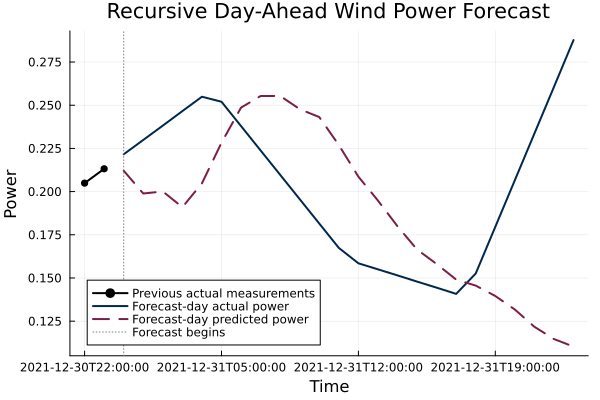

In [18]:

using CSV
using DataFrames
using Dates
using Statistics
using LinearAlgebra
using Random
using Plots

Random.seed!(42)

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort the data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

# Select the final calendar day as the forecast day
dates = Date.(data.Time)
forecast_date = maximum(dates)
forecast_idx = findall(dates .== forecast_date)
first_idx = first(forecast_idx)
train_end = first_idx - 1

if first_idx <= 2
    error("Not enough preceding measurements to initialize the forecast.")
end

if data.Time[first_idx] - data.Time[first_idx - 1] != Hour(1) ||
   data.Time[first_idx - 1] - data.Time[first_idx - 2] != Hour(1)
    error("The two measurements before the forecast day must be consecutive hourly observations.")
end

# Extract features
t = Float64.(data.Power)
x = Float64.(data.windspeed_10m) ./ 10.0
z = Float64.(data.windspeed_100m) ./ 10.0
windgust = Float64.(data.windgusts_10m) ./ 10.0

hour = Float64.(Dates.hour.(data.Time))
hour_sin = sin.(2π .* hour ./ 24)
hour_cos = cos.(2π .* hour ./ 24)

# Use only training-period observations with two consecutive hourly lags
train_idx = [
    i for i in 3:train_end
    if data.Time[i] - data.Time[i - 1] == Hour(1) &&
       data.Time[i - 1] - data.Time[i - 2] == Hour(1)
]

if isempty(train_idx)
    error("No valid training rows with two consecutive hourly lags were found.")
end

# Build training features from actual historical power
lag1_train = t[train_idx .- 1]
lag2_train = t[train_idx .- 2]
y_train = t[train_idx]

# Standardize lag features using training data only
lag1_mean = mean(lag1_train)
lag1_std = std(lag1_train)
lag2_mean = mean(lag2_train)
lag2_std = std(lag2_train)

lag1_std = lag1_std == 0 ? 1.0 : lag1_std
lag2_std = lag2_std == 0 ? 1.0 : lag2_std

lag1_train_z = (lag1_train .- lag1_mean) ./ lag1_std
lag2_train_z = (lag2_train .- lag2_mean) ./ lag2_std

# Standardize the target to improve numerical stability
y_mean = mean(y_train)
y_std = std(y_train)
y_std = y_std == 0 ? 1.0 : y_std
y_train_z = (y_train .- y_mean) ./ y_std

# Gaussian RBF transformation
c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

# Construct RBF feature matrices
function make_rbf_matrix(values, centers)
    Φ = zeros(length(values), length(centers))
    for i in eachindex(values), j in eachindex(centers)
        Φ[i, j] = φ(values[i], j)
    end
    return Φ
end

Φ_10 = make_rbf_matrix(x[train_idx], c)
Φ_100 = make_rbf_matrix(z[train_idx], c)
Φ_gust = make_rbf_matrix(windgust[train_idx], c)

# Model parameters
w_0 = 0.0
w_10 = zeros(num_centers)
w_100 = zeros(num_centers)
w_gust = zeros(num_centers)

β_lag1 = 0.0
β_lag2 = 0.0
β_hour_sin = 0.0
β_hour_cos = 0.0

# SGD settings
α = 0.01
iter_max = 25_000
λ = 0.01

n_train = length(train_idx)

# Train the model
for iteration in 1:iter_max
    k = rand(1:n_train)

    y_hat = w_0 +
            dot(w_10, view(Φ_10, k, :)) +
            dot(w_100, view(Φ_100, k, :)) +
            dot(w_gust, view(Φ_gust, k, :)) +
            β_lag1 * lag1_train_z[k] +
            β_lag2 * lag2_train_z[k] +
            β_hour_sin * hour_sin[train_idx[k]] +
            β_hour_cos * hour_cos[train_idx[k]]

    err = y_hat - y_train_z[k]

    # Update intercept
    w_0 -= α * err

    # Update nonlinear RBF weights
    w_10 .-= α .* (err .* view(Φ_10, k, :) .+ λ .* w_10)
    w_100 .-= α .* (err .* view(Φ_100, k, :) .+ λ .* w_100)
    w_gust .-= α .* (err .* view(Φ_gust, k, :) .+ λ .* w_gust)

    # Update lagged-power coefficients
    β_lag1 -= α * (err * lag1_train_z[k] + λ * β_lag1)
    β_lag2 -= α * (err * lag2_train_z[k] + λ * β_lag2)

    # Update time-of-day coefficients
    β_hour_sin -= α * (err * hour_sin[train_idx[k]] + λ * β_hour_sin)
    β_hour_cos -= α * (err * hour_cos[train_idx[k]] + λ * β_hour_cos)
end

# Prediction function: all features are included
function predict_power(i, lag1_value, lag2_value)
    lag1_z = (lag1_value - lag1_mean) / lag1_std
    lag2_z = (lag2_value - lag2_mean) / lag2_std

    rbf10 = [φ(x[i], j) for j in eachindex(c)]
    rbf100 = [φ(z[i], j) for j in eachindex(c)]
    rbfgust = [φ(windgust[i], j) for j in eachindex(c)]

    prediction_z = w_0 +
                   dot(w_10, rbf10) +
                   dot(w_100, rbf100) +
                   dot(w_gust, rbfgust) +
                   β_lag1 * lag1_z +
                   β_lag2 * lag2_z +
                   β_hour_sin * hour_sin[i] +
                   β_hour_cos * hour_cos[i]

    return prediction_z * y_std + y_mean
end

# Initialize the forecast with the two actual measurements before the day
previous_power_1 = t[first_idx - 1]
previous_power_2 = t[first_idx - 2]

predicted_power = Float64[]

# Recursively forecast the selected day
for i in forecast_idx
    prediction = predict_power(i, previous_power_1, previous_power_2)
    push!(predicted_power, prediction)

    # Future lag inputs come from the model's own predictions
    previous_power_2 = previous_power_1
    previous_power_1 = prediction
end

# Actual and predicted power for the forecast day
actual_power = t[forecast_idx]
forecast_time = data.Time[forecast_idx]

rmse = sqrt(mean((predicted_power .- actual_power).^2))
mae = mean(abs.(predicted_power .- actual_power))

println("Forecast date: ", forecast_date)
println("Training observations: ", length(train_idx))
println("Forecast observations: ", length(forecast_idx))
println("RMSE: ", rmse)
println("MAE: ", mae)

# Plot the two actual measurements immediately before the forecast day
history_idx = (first_idx - 2):(first_idx - 1)
history_time = data.Time[history_idx]
history_power = t[history_idx]

plot(
    history_time,
    history_power;
    label = "Previous actual measurements",
    color = :black,
    marker = :circle,
    linewidth = 2
)

plot!(
    forecast_time,
    actual_power;
    label = "Forecast-day actual power",
    color = blue,
    linewidth = 2
)

plot!(
    forecast_time,
    predicted_power;
    label = "Forecast-day predicted power",
    color = purple,
    linestyle = :dash,
    linewidth = 2
)

vline!(
    [forecast_time[1]];
    label = "Forecast begins",
    color = :gray,
    linestyle = :dot
)

xlabel!("Time")
ylabel!("Power")
title!("Recursive Day-Ahead Wind Power Forecast")



--- Forecast initialization diagnostics ---
Last actual power: 0.2132
First predicted power: 0.19091851596523735

Four actual lag values:
[0.1882, 0.1966, 0.2049, 0.2132]

Four learned lag coefficients:
[0.93073718610593, 0.2918301804877312, -0.06547007172710954, -0.21974097678529922]

Time-of-day contribution:
sin contribution = -0.0
cos contribution = 0.0003536511185128176

Wind feature contributions:
10 m wind = -0.025154885947260452
100 m wind = -0.06512533030919422
Wind gust = 0.04025413201522957
Forecast date: 2021-12-31
Previous four actual power measurements:
2021-12-30T20:00:00 : 0.1882
2021-12-30T21:00:00 : 0.1966
2021-12-30T22:00:00 : 0.2049
2021-12-30T23:00:00 : 0.2132

Training observations: 43772
Forecast observations: 24
RMSE: 0.047152289412535506
MAE: 0.04008612487590129


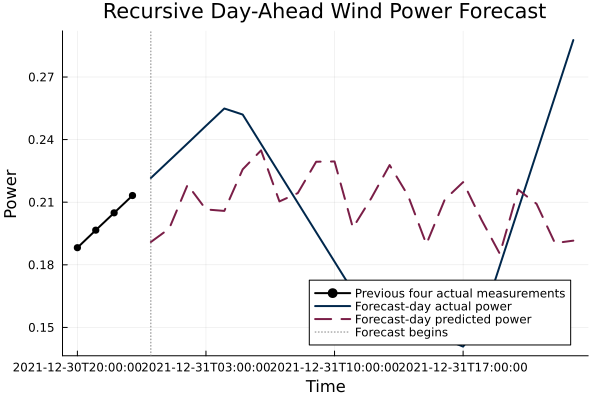

In [20]:

using CSV
using DataFrames
using Dates
using Statistics
using LinearAlgebra
using Random
using Plots

Random.seed!(42)

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

# Select the final calendar day as the forecast day
dates = Date.(data.Time)
forecast_date = maximum(dates)
forecast_idx = findall(dates .== forecast_date)

if isempty(forecast_idx)
    error("No observations found for the forecast day.")
end

first_idx = first(forecast_idx)
train_end = first_idx - 1

if first_idx <= 4
    error("Not enough historical measurements to initialize four power lags.")
end

# Verify the four preceding observations are consecutive hourly measurements
for j in (first_idx - 3):(first_idx - 1)
    if data.Time[j] - data.Time[j - 1] != Hour(1)
        error("The four measurements before the forecast day must be consecutive hourly observations.")
    end
end

# Extract target and wind features
t = Float64.(data.Power)
x = Float64.(data.windspeed_10m) ./ 10.0
z = Float64.(data.windspeed_100m) ./ 10.0
windgust = Float64.(data.windgusts_10m) ./ 10.0

# Time-of-day features
hour = Float64.(Dates.hour.(data.Time))
hour_sin = sin.(2π .* hour ./ 24)
hour_cos = cos.(2π .* hour ./ 24)

# Identify training rows with four consecutive hourly power measurements
train_idx = [
    i for i in 5:train_end
    if all(
        data.Time[j] - data.Time[j - 1] == Hour(1)
        for j in (i - 3):i
    )
]

if isempty(train_idx)
    error("No valid training rows with four consecutive hourly power lags were found.")
end

# Training target
y_train = t[train_idx]

# Four historical power lag features
lag_train = [t[train_idx .- k] for k in 1:4]

# Standardize lag features using training data only
lag_means = [mean(lag) for lag in lag_train]
lag_stds = [std(lag) for lag in lag_train]
lag_stds = [
    !isfinite(s) || s == 0 ? 1.0 : s
    for s in lag_stds
]

lag_train_z = [
    (lag_train[k] .- lag_means[k]) ./ lag_stds[k]
    for k in 1:4
]

# Standardize target
y_mean = mean(y_train)
y_std = std(y_train)
y_std = !isfinite(y_std) || y_std == 0 ? 1.0 : y_std
y_train_z = (y_train .- y_mean) ./ y_std

# Gaussian RBF transformation
c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

function make_rbf_matrix(values, centers)
    Φ = zeros(length(values), length(centers))
    for i in eachindex(values), j in eachindex(centers)
        Φ[i, j] = φ(values[i], j)
    end
    return Φ
end

# RBF matrices for training data
Φ_10 = make_rbf_matrix(x[train_idx], c)
Φ_100 = make_rbf_matrix(z[train_idx], c)
Φ_gust = make_rbf_matrix(windgust[train_idx], c)

# Model parameters
w_0 = 0.0
w_10 = zeros(num_centers)
w_100 = zeros(num_centers)
w_gust = zeros(num_centers)

β_lags = zeros(4)
β_hour_sin = 0.0
β_hour_cos = 0.0

# SGD settings
α = 0.01
iter_max = 25_000
λ = 0.01

n_train = length(train_idx)

# Train the model
for iteration in 1:iter_max
    k = rand(1:n_train)

    y_hat = w_0 +
            dot(w_10, view(Φ_10, k, :)) +
            dot(w_100, view(Φ_100, k, :)) +
            dot(w_gust, view(Φ_gust, k, :)) +
            sum(β_lags[j] * lag_train_z[j][k] for j in 1:4) +
            β_hour_sin * hour_sin[train_idx[k]] +
            β_hour_cos * hour_cos[train_idx[k]]

    err = y_hat - y_train_z[k]

    # Update intercept
    w_0 -= α * err

    # Update nonlinear RBF weights
    w_10 .-= α .* (err .* view(Φ_10, k, :) .+ λ .* w_10)
    w_100 .-= α .* (err .* view(Φ_100, k, :) .+ λ .* w_100)
    w_gust .-= α .* (err .* view(Φ_gust, k, :) .+ λ .* w_gust)

    # Update four lag coefficients
    for j in 1:4
        β_lags[j] -= α * (
            err * lag_train_z[j][k] + λ * β_lags[j]
        )
    end

    # Update time-of-day coefficients
    β_hour_sin -= α * (
        err * hour_sin[train_idx[k]] + λ * β_hour_sin
    )
    β_hour_cos -= α * (
        err * hour_cos[train_idx[k]] + λ * β_hour_cos
    )
end

# Prediction function
function predict_power(i, lag_values)
    lag_z = [
        (lag_values[j] - lag_means[j]) / lag_stds[j]
        for j in 1:4
    ]

    rbf10 = [φ(x[i], j) for j in eachindex(c)]
    rbf100 = [φ(z[i], j) for j in eachindex(c)]
    rbfgust = [φ(windgust[i], j) for j in eachindex(c)]

    prediction_z = w_0 +
                   dot(w_10, rbf10) +
                   dot(w_100, rbf100) +
                   dot(w_gust, rbfgust) +
                   sum(β_lags[j] * lag_z[j] for j in 1:4) +
                   β_hour_sin * hour_sin[i] +
                   β_hour_cos * hour_cos[i]

    return prediction_z * y_std + y_mean
end

println("\n--- Forecast initialization diagnostics ---")

println("Last actual power: ", t[first_idx - 1])
println("First predicted power: ", predict_power(
    first_idx,
    collect(t[(first_idx - 4):(first_idx - 1)])
))

println("\nFour actual lag values:")
println(collect(t[(first_idx - 4):(first_idx - 1)]))

println("\nFour learned lag coefficients:")
println(β_lags)

println("\nTime-of-day contribution:")
println("sin contribution = ",
    β_hour_sin * hour_sin[first_idx])
println("cos contribution = ",
    β_hour_cos * hour_cos[first_idx])

println("\nWind feature contributions:")
println("10 m wind = ",
    dot(w_10, [φ(x[first_idx], j) for j in eachindex(c)]))
println("100 m wind = ",
    dot(w_100, [φ(z[first_idx], j) for j in eachindex(c)]))
println("Wind gust = ",
    dot(w_gust, [φ(windgust[first_idx], j) for j in eachindex(c)]))

# Initialize using the four actual power measurements before forecast day
lag_values = collect(t[(first_idx - 4):(first_idx - 1)])

println("Forecast date: ", forecast_date)
println("Previous four actual power measurements:")
for j in (first_idx - 4):(first_idx - 1)
    println(data.Time[j], " : ", t[j])
end


# Recursive forecast for the selected day
predicted_power = Float64[]

for i in forecast_idx
    prediction = predict_power(i, lag_values)
    push!(predicted_power, prediction)

    # Shift the lag window and append the new prediction
    popfirst!(lag_values)
    push!(lag_values, prediction)
end

# Actual forecast-day observations
actual_power = t[forecast_idx]
forecast_time = data.Time[forecast_idx]

# Calculate forecast metrics
rmse = sqrt(mean((predicted_power .- actual_power).^2))
mae = mean(abs.(predicted_power .- actual_power))

println("\nTraining observations: ", length(train_idx))
println("Forecast observations: ", length(forecast_idx))
println("RMSE: ", rmse)
println("MAE: ", mae)

# Plot the four actual measurements before the forecast day
history_idx = (first_idx - 4):(first_idx - 1)
history_time = data.Time[history_idx]
history_power = t[history_idx]

plot(
    history_time,
    history_power;
    label = "Previous four actual measurements",
    color = :black,
    marker = :circle,
    linewidth = 2
)

plot!(
    forecast_time,
    actual_power;
    label = "Forecast-day actual power",
    color = blue,
    linewidth = 2
)

plot!(
    forecast_time,
    predicted_power;
    label = "Forecast-day predicted power",
    color = purple,
    linestyle = :dash,
    linewidth = 2
)

vline!(
    [forecast_time[1]];
    label = "Forecast begins",
    color = :gray,
    linestyle = :dot
)

xlabel!("Time")
ylabel!("Power")
title!("Recursive Day-Ahead Wind Power Forecast")


Random validation date: 2020-03-13
Number of eligible validation days: 1824
Training ends at: 2020-03-12T23:00:00

Four preceding actual power measurements:
2020-03-12T20:00:00 : 0.5483
2020-03-12T21:00:00 : 0.5976
2020-03-12T22:00:00 : 0.6469
2020-03-12T23:00:00 : 0.6962

========== MODEL PERFORMANCE ==========
Validation date: 2020-03-13
Training observations: 27980
Validation observations: 24
RMSE = 0.2746761037953155
MAE  = 0.25182932529964586
β_100 = 0.0
β_windgust = 0.0
β_lags = [0.2674978195622405, 0.08403154061020023, -0.019788050213131875, -0.06815201182434395]
β_hour_sin = 0.0035113215347518005
β_hour_cos = 0.006932943051489903


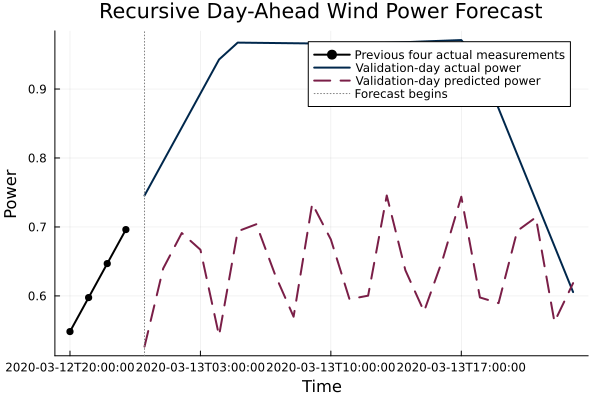

In [31]:

using CSV
using DataFrames
using Dates
using Statistics
using LinearAlgebra
using Random
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

# Extract power and weather data
t = Float64.(data.Power)
x = Float64.(data.windspeed_10m) ./ 10.0
z = Float64.(data.windspeed_100m) ./ 10.0
windgust = Float64.(data.windgusts_10m) ./ 10.0

time = data.Time
dates = Date.(time)
unique_dates = sort(unique(dates))

# Find eligible validation days
eligible_dates = Date[]

for d in unique_dates
    day_idx = findall(dates .== d)
    first_day_idx = first(day_idx)

    # Require four observations before the validation day
    if first_day_idx <= 4
        continue
    end

    # Require four consecutive hourly observations before the day
    valid_history = all(
        time[j] - time[j - 1] == Hour(1)
        for j in (first_day_idx - 3):(first_day_idx - 1)
    )

    # Require 24 consecutive hourly observations on the validation day
    valid_day = length(day_idx) == 24 &&
        all(
            time[day_idx[j]] - time[day_idx[j - 1]] == Hour(1)
            for j in 2:length(day_idx)
        )

    # Ensure there are earlier rows available for training
    if valid_history && valid_day && first_day_idx > 5
        push!(eligible_dates, d)
    end
end

if isempty(eligible_dates)
    error("No eligible validation days found. Check for missing hourly data.")
end

# Randomly select a validation day
# No fixed seed: selection can change each run
forecast_date = rand(eligible_dates)
forecast_idx = findall(dates .== forecast_date)

first_idx = first(forecast_idx)
train_end = first_idx - 1

println("Random validation date: ", forecast_date)
println("Number of eligible validation days: ", length(eligible_dates))
println("Training ends at: ", time[train_end])

# Time-of-day features
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# Build training rows using data before the validation day only
train_idx = [
    i for i in 5:train_end
    if all(
        time[j] - time[j - 1] == Hour(1)
        for j in (i - 3):i
    )
]

if isempty(train_idx)
    error("No valid training rows found before the selected validation day.")
end

n_train = length(train_idx)
y_train = t[train_idx]

# Four lagged power inputs
lag_train = [
    t[train_idx .- k] for k in 1:4
]

# Standardize lagged power using training data only
lag_means = [mean(v) for v in lag_train]
lag_stds = [std(v) for v in lag_train]

lag_stds = [
    !isfinite(s) || s == 0 ? 1.0 : s
    for s in lag_stds
]

lag_train_z = [
    (lag_train[k] .- lag_means[k]) ./ lag_stds[k]
    for k in 1:4
]

# RBF model parameters
α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

# Build RBF feature matrices
function make_rbf_matrix(values, centers)
    Φ = zeros(length(values), length(centers))

    for i in eachindex(values)
        for j in eachindex(centers)
            Φ[i, j] = φ(values[i], j)
        end
    end

    return Φ
end

Φ_10 = make_rbf_matrix(x[train_idx], c)
Φ_100 = make_rbf_matrix(z[train_idx], c)
Φ_gust = make_rbf_matrix(windgust[train_idx], c)

# Initialize model parameters
w_0 = mean(y_train)

w_10 = zeros(num_centers)
w_100 = zeros(num_centers)
w_gust = zeros(num_centers)

β_100 = 0.0
β_windgust = 0.0
β_lags = zeros(4)

β_hour_sin = 0.0
β_hour_cos = 0.0

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n_train)

    ϕ10_i = view(Φ_10, i, :)
    ϕ100_i = view(Φ_100, i, :)
    ϕgust_i = view(Φ_gust, i, :)

    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    f_lags = sum(
        β_lags[k] * lag_train_z[k][i]
        for k in 1:4
    )

    f_time = β_hour_sin * hour_sin[train_idx[i]] +
             β_hour_cos * hour_cos[train_idx[i]]

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust +
            f_lags +
            f_time

    error = y_hat - y_train[i]

    # Update intercept
    w_0 -= α * error

    # Update RBF weights
    w_10 .-= α .* error .* ϕ10_i
    w_100 .-= α .* error .* β_100 .* ϕ100_i
    w_gust .-= α .* error .* β_windgust .* ϕgust_i

    # Update wind-feature scaling coefficients
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust

    # Update four lag coefficients
    for k in 1:4
        β_lags[k] -= α * error * lag_train_z[k][i]
    end

    # Update time-of-day coefficients
    β_hour_sin -= α * error * hour_sin[train_idx[i]]
    β_hour_cos -= α * error * hour_cos[train_idx[i]]

    # Regularization
    if reg_type == "l2"
        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

        β_lags .-= α * λ .* β_lags

        β_hour_sin -= α * λ * β_hour_sin
        β_hour_cos -= α * λ * β_hour_cos

    elseif reg_type == "l1"
        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)

        β_lags .= sign.(β_lags) .* max.(0, abs.(β_lags) .- α * λ)

        β_hour_sin = sign(β_hour_sin) *
                     max(0, abs(β_hour_sin) - α * λ)
        β_hour_cos = sign(β_hour_cos) *
                     max(0, abs(β_hour_cos) - α * λ)
    end
end

# Prediction function
function predict_power(i, lag_values)

    lag_z = [
        (lag_values[k] - lag_means[k]) / lag_stds[k]
        for k in 1:4
    ]

    f_10 = sum(
        w_10[j] * φ(x[i], j)
        for j in 1:num_centers
    )

    f_100 = sum(
        w_100[j] * φ(z[i], j)
        for j in 1:num_centers
    )

    f_gust = sum(
        w_gust[j] * φ(windgust[i], j)
        for j in 1:num_centers
    )

    f_lags = sum(
        β_lags[k] * lag_z[k]
        for k in 1:4
    )

    f_time = β_hour_sin * hour_sin[i] +
             β_hour_cos * hour_cos[i]

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust +
           f_lags +
           f_time
end

# Initialize with four actual observations immediately before the day
lag_values = collect(t[(first_idx - 4):(first_idx - 1)])

println("\nFour preceding actual power measurements:")
for j in (first_idx - 4):(first_idx - 1)
    println(time[j], " : ", t[j])
end

# Recursive 24-hour forecast
predicted_power = Float64[]

for i in forecast_idx
    prediction = predict_power(i, lag_values)
    push!(predicted_power, prediction)

    # Use the prediction as the newest lag for the next hour
    popfirst!(lag_values)
    push!(lag_values, prediction)
end

# Actual validation-day power
actual_power = t[forecast_idx]
forecast_time = time[forecast_idx]

# Performance metrics
errors = predicted_power .- actual_power
RMSE = sqrt(mean(errors .^ 2))
MAE = mean(abs.(errors))

println("\n========== MODEL PERFORMANCE ==========")
println("Validation date: ", forecast_date)
println("Training observations: ", n_train)
println("Validation observations: ", length(forecast_idx))
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("β_lags = ", β_lags)
println("β_hour_sin = ", β_hour_sin)
println("β_hour_cos = ", β_hour_cos)
println("=======================================")

# Plot the four preceding actual observations
# and the full validation day
history_idx = (first_idx - 4):(first_idx - 1)

plot(
    time[history_idx],
    t[history_idx];
    label = "Previous four actual measurements",
    color = :black,
    marker = :circle,
    linewidth = 2
)

plot!(
    forecast_time,
    actual_power;
    label = "Validation-day actual power",
    color = blue,
    linewidth = 2
)

plot!(
    forecast_time,
    predicted_power;
    label = "Validation-day predicted power",
    color = purple,
    linestyle = :dash,
    linewidth = 2
)

vline!(
    [forecast_time[1]];
    label = "Forecast begins",
    color = :gray,
    linestyle = :dot
)

xlabel!("Time")
ylabel!("Power")
title!("Recursive Day-Ahead Wind Power Forecast")


Random validation date: 2018-10-01
Eligible validation days: 1824
Training ends at: 2018-09-30T23:00:00

Four preceding actual power measurements:
2018-09-30T20:00:00 : 0.1824
2018-09-30T21:00:00 : 0.2062
2018-09-30T22:00:00 : 0.2301
2018-09-30T23:00:00 : 0.2539

========== MODEL PERFORMANCE ==========
Validation date: 2018-10-01
Training observations: 15284
Validation observations: 24
RMSE = 0.13952611689805453
MAE  = 0.12001355153554671
β_100 = 0.0
β_windgust = 0.0
β_lags = [0.2743270840954107, 0.08760745480545692, -0.019293499163841512, -0.07075584340382943]
Norm w_10 = 0.010763306109051601
Norm w_100 = 0.0
Norm w_gust = 0.0


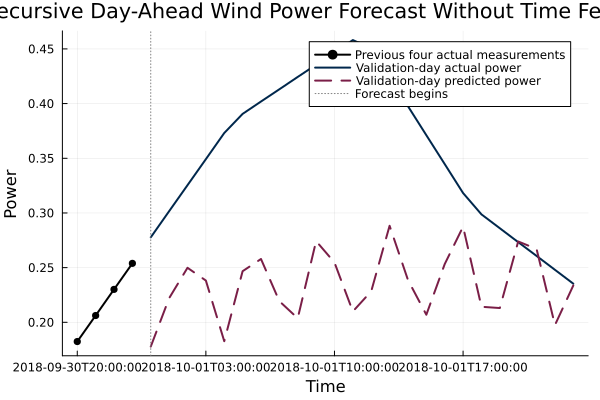

In [ ]:


purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

# Extract power and weather data
t = Float64.(data.Power)
x = Float64.(data.windspeed_10m) ./ 10.0
z = Float64.(data.windspeed_100m) ./ 10.0
windgust = Float64.(data.windgusts_10m) ./ 10.0

time = data.Time
dates = Date.(time)
unique_dates = sort(unique(dates))

# Find eligible validation days
eligible_dates = Date[]

for d in unique_dates
    day_idx = findall(dates .== d)
    first_day_idx = first(day_idx)

    # Require four preceding observations
    if first_day_idx <= 4
        continue
    end

    # Require four consecutive hourly observations before the day
    valid_history = all(
        time[j] - time[j - 1] == Hour(1)
        for j in (first_day_idx - 3):(first_day_idx - 1)
    )

    # Require 24 consecutive hourly observations on the validation day
    valid_day = length(day_idx) == 24 &&
        all(
            time[day_idx[j]] - time[day_idx[j - 1]] == Hour(1)
            for j in 2:length(day_idx)
        )

    if valid_history && valid_day && first_day_idx > 5
        push!(eligible_dates, d)
    end
end

if isempty(eligible_dates)
    error("No eligible validation days found. Check for missing hourly data.")
end

# Select a random validation day on each run
forecast_date = rand(eligible_dates)
forecast_idx = findall(dates .== forecast_date)

first_idx = first(forecast_idx)
train_end = first_idx - 1

println("Random validation date: ", forecast_date)
println("Eligible validation days: ", length(eligible_dates))
println("Training ends at: ", time[train_end])

# Build training rows using only observations before validation day
train_idx = [
    i for i in 5:train_end
    if all(
        time[j] - time[j - 1] == Hour(1)
        for j in (i - 3):i
    )
]

if isempty(train_idx)
    error("No valid training rows found before the selected validation day.")
end

n_train = length(train_idx)
y_train = t[train_idx]

# Four lagged power inputs
lag_train = [
    t[train_idx .- k] for k in 1:4
]

# Standardize lagged power using training data only
lag_means = [mean(v) for v in lag_train]
lag_stds = [std(v) for v in lag_train]

lag_stds = [
    !isfinite(s) || s == 0 ? 1.0 : s
    for s in lag_stds
]

lag_train_z = [
    (lag_train[k] .- lag_means[k]) ./ lag_stds[k]
    for k in 1:4
]

# RBF model parameters
α = 0.01
iter_max = 25_000
λ = 0.01
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function φ(x_value, j)
    return exp(-(γ * abs(x_value - c[j]))^2)
end

# Build RBF feature matrices
function make_rbf_matrix(values, centers)
    Φ = zeros(length(values), length(centers))

    for i in eachindex(values)
        for j in eachindex(centers)
            Φ[i, j] = φ(values[i], j)
        end
    end

    return Φ
end

Φ_10 = make_rbf_matrix(x[train_idx], c)
Φ_100 = make_rbf_matrix(z[train_idx], c)
Φ_gust = make_rbf_matrix(windgust[train_idx], c)

# Initialize model parameters
w_0 = mean(y_train)

w_10 = zeros(num_centers)
w_100 = zeros(num_centers)
w_gust = zeros(num_centers)

β_100 = 0.0
β_windgust = 0.0
β_lags = zeros(4)

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n_train)

    ϕ10_i = view(Φ_10, i, :)
    ϕ100_i = view(Φ_100, i, :)
    ϕgust_i = view(Φ_gust, i, :)

    f_10 = dot(ϕ10_i, w_10)
    f_100 = dot(ϕ100_i, w_100)
    f_gust = dot(ϕgust_i, w_gust)

    f_lags = sum(
        β_lags[k] * lag_train_z[k][i]
        for k in 1:4
    )

    y_hat = w_0 +
            f_10 +
            β_100 * f_100 +
            β_windgust * f_gust +
            f_lags

    error = y_hat - y_train[i]

    # Update intercept
    w_0 -= α * error

    # Update RBF weights
    w_10 .-= α .* error .* ϕ10_i
    w_100 .-= α .* error .* β_100 .* ϕ100_i
    w_gust .-= α .* error .* β_windgust .* ϕgust_i

    # Update wind-feature scaling coefficients
    β_100 -= α * error * f_100
    β_windgust -= α * error * f_gust

    # Update four lag coefficients
    for k in 1:4
        β_lags[k] -= α * error * lag_train_z[k][i]
    end

    # Regularization
    if reg_type == "l2"
        w_10 .-= α * λ .* w_10
        w_100 .-= α * λ .* w_100
        w_gust .-= α * λ .* w_gust

        β_100 -= α * λ * β_100
        β_windgust -= α * λ * β_windgust

        β_lags .-= α * λ .* β_lags

    elseif reg_type == "l1"
        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)

        β_100 = sign(β_100) * max(0, abs(β_100) - α * λ)
        β_windgust = sign(β_windgust) *
                     max(0, abs(β_windgust) - α * λ)

        β_lags .= sign.(β_lags) .* max.(0, abs.(β_lags) .- α * λ)
    end
end

# Prediction function without time features
function predict_power(i, lag_values)

    lag_z = [
        (lag_values[k] - lag_means[k]) / lag_stds[k]
        for k in 1:4
    ]

    f_10 = sum(
        w_10[j] * φ(x[i], j)
        for j in 1:num_centers
    )

    f_100 = sum(
        w_100[j] * φ(z[i], j)
        for j in 1:num_centers
    )

    f_gust = sum(
        w_gust[j] * φ(windgust[i], j)
        for j in 1:num_centers
    )

    f_lags = sum(
        β_lags[k] * lag_z[k]
        for k in 1:4
    )

    return w_0 +
           f_10 +
           β_100 * f_100 +
           β_windgust * f_gust +
           f_lags
end

# Initialize with four actual measurements before validation day
lag_values = collect(t[(first_idx - 4):(first_idx - 1)])

println("\nFour preceding actual power measurements:")
for j in (first_idx - 4):(first_idx - 1)
    println(time[j], " : ", t[j])
end

# Recursive 24-hour forecast
predicted_power = Float64[]

for i in forecast_idx
    prediction = predict_power(i, lag_values)
    push!(predicted_power, prediction)

    # Use prediction as the newest lag for the next hour
    popfirst!(lag_values)
    push!(lag_values, prediction)
end

# Actual validation-day power
actual_power = t[forecast_idx]
forecast_time = time[forecast_idx]

# Performance metrics
errors = predicted_power .- actual_power
RMSE = sqrt(mean(errors .^ 2))
MAE = mean(abs.(errors))

println("\n========== MODEL PERFORMANCE ==========")
println("Validation date: ", forecast_date)
println("Training observations: ", n_train)
println("Validation observations: ", length(forecast_idx))
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("β_100 = ", β_100)
println("β_windgust = ", β_windgust)
println("β_lags = ", β_lags)
println("Norm w_10 = ", norm(w_10))
println("Norm w_100 = ", norm(w_100))
println("Norm w_gust = ", norm(w_gust))
println("=======================================")

# Plot preceding measurements and validation-day results
history_idx = (first_idx - 4):(first_idx - 1)

plot(
    time[history_idx],
    t[history_idx];
    label = "Previous four actual measurements",
    color = :black,
    marker = :circle,
    linewidth = 2
)

plot!(
    forecast_time,
    actual_power;
    label = "Validation-day actual power",
    color = blue,
    linewidth = 2
)

plot!(
    forecast_time,
    predicted_power;
    label = "Validation-day predicted power",
    color = purple,
    linestyle = :dash,
    linewidth = 2
)

vline!(
    [forecast_time[1]];
    label = "Forecast begins",
    color = :gray,
    linestyle = :dot
)

xlabel!("Time")
ylabel!("Power")
title!("Recursive Day-Ahead Wind Power Forecast Without Time Features")


Random validation date: 2021-06-12
Eligible validation days: 1824
Training ends at: 2021-06-11T23:00:00

========== MODEL PERFORMANCE ==========
Validation date: 2021-06-12
Training observations: 38928
Validation observations: 24
RMSE = 0.10198951182963645
MAE  = 0.08384127553746125
Norm w_10 = 0.14617097493384268
Norm w_100 = 0.3026430023526911
Norm w_gust = 0.05871184107523349


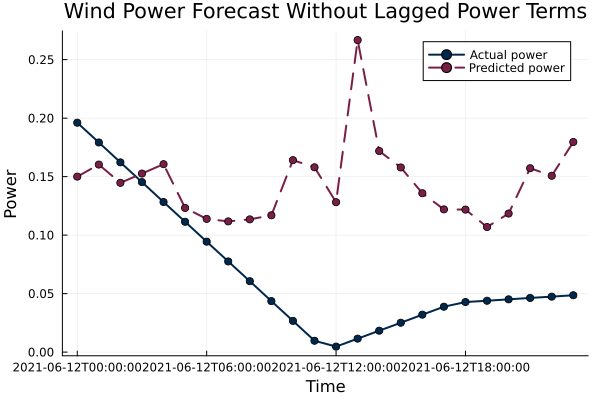

In [58]:

using CSV
using DataFrames
using Dates
using Statistics
using LinearAlgebra
using Random
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

# Extract power and weather data
t = Float64.(data.Power)
x = Float64.(data.windspeed_10m) ./ 10.0
z = Float64.(data.windspeed_100m) ./ 10.0
windgust = Float64.(data.windgusts_10m) ./ 10.0

time = data.Time
dates = Date.(time)
unique_dates = sort(unique(dates))

# Find eligible validation days with 24 consecutive hourly observations
eligible_dates = Date[]

for d in unique_dates
    day_idx = findall(dates .== d)

    valid_day = length(day_idx) == 24 &&
        all(
            time[day_idx[j]] - time[day_idx[j - 1]] == Hour(1)
            for j in 2:length(day_idx)
        )

    if valid_day && first(day_idx) > 1
        push!(eligible_dates, d)
    end
end

if isempty(eligible_dates)
    error("No complete 24-hour validation days found.")
end

# Randomly select a validation day
forecast_date = rand(eligible_dates)
forecast_idx = findall(dates .== forecast_date)

first_idx = first(forecast_idx)
train_end = first_idx - 1

println("Random validation date: ", forecast_date)
println("Eligible validation days: ", length(eligible_dates))
println("Training ends at: ", time[train_end])

# Keep only valid training observations before the validation day
train_idx = [
    i for i in 1:train_end
    if isfinite(t[i]) &&
       isfinite(x[i]) &&
       isfinite(z[i]) &&
       isfinite(windgust[i])
]

if length(train_idx) < 10
    error("Not enough valid training observations.")
end

y_train = t[train_idx]
n_train = length(train_idx)

# RBF model parameters
α = 0.01
iter_max = 25_000
λ = 0.001
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function rbf(value, centers, gamma)
    return exp.(-((gamma .* abs.(value .- centers)).^2))
end

# Construct RBF feature matrices
function make_rbf_matrix(values, centers, gamma)
    Φ = zeros(length(values), length(centers))

    for i in eachindex(values)
        Φ[i, :] = rbf(values[i], centers, gamma)
    end

    return Φ
end

Φ_10 = make_rbf_matrix(x[train_idx], c, γ)
Φ_100 = make_rbf_matrix(z[train_idx], c, γ)
Φ_gust = make_rbf_matrix(windgust[train_idx], c, γ)

# Initialize model parameters
w_0 = mean(y_train)

w_10 = zeros(num_centers)
w_100 = zeros(num_centers)
w_gust = zeros(num_centers)

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n_train)

    ϕ10_i = view(Φ_10, i, :)
    ϕ100_i = view(Φ_100, i, :)
    ϕgust_i = view(Φ_gust, i, :)

    # Prediction using weather features only
    y_hat = w_0 +
            dot(w_10, ϕ10_i) +
            dot(w_100, ϕ100_i) +
            dot(w_gust, ϕgust_i)

    error = y_hat - y_train[i]

    # Calculate gradients from the same parameter state
    grad_10 = error .* ϕ10_i
    grad_100 = error .* ϕ100_i
    grad_gust = error .* ϕgust_i

    # Update parameters
    w_0 -= α * error

    if reg_type == "l2"
        w_10 .-= α .* (grad_10 .+ λ .* w_10)
        w_100 .-= α .* (grad_100 .+ λ .* w_100)
        w_gust .-= α .* (grad_gust .+ λ .* w_gust)

    elseif reg_type == "l1"
        w_10 .-= α .* grad_10
        w_100 .-= α .* grad_100
        w_gust .-= α .* grad_gust

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)
    end
end

# Build validation-day weather features
Φ_10_val = make_rbf_matrix(x[forecast_idx], c, γ)
Φ_100_val = make_rbf_matrix(z[forecast_idx], c, γ)
Φ_gust_val = make_rbf_matrix(windgust[forecast_idx], c, γ)

# Predict all 24 hours independently
predicted_power = zeros(length(forecast_idx))

for i in eachindex(forecast_idx)
    predicted_power[i] = w_0 +
        dot(w_10, view(Φ_10_val, i, :)) +
        dot(w_100, view(Φ_100_val, i, :)) +
        dot(w_gust, view(Φ_gust_val, i, :))
end

# Actual validation-day power
actual_power = t[forecast_idx]
forecast_time = time[forecast_idx]

# Calculate performance metrics
valid_eval = [
    i for i in eachindex(actual_power)
    if isfinite(actual_power[i]) && isfinite(predicted_power[i])
]

if isempty(valid_eval)
    error("No valid observations available for validation metrics.")
end

errors = predicted_power[valid_eval] .- actual_power[valid_eval]
RMSE = sqrt(mean(errors .^ 2))
MAE = mean(abs.(errors))

println("\n========== MODEL PERFORMANCE ==========")
println("Validation date: ", forecast_date)
println("Training observations: ", n_train)
println("Validation observations: ", length(valid_eval))
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("Norm w_10 = ", norm(w_10))
println("Norm w_100 = ", norm(w_100))
println("Norm w_gust = ", norm(w_gust))
println("=======================================")

# Plot actual versus predicted power
plot(
    forecast_time,
    actual_power;
    label = "Actual power",
    color = blue,
    linewidth = 2,
    marker = :circle
)

plot!(
    forecast_time,
    predicted_power;
    label = "Predicted power",
    color = purple,
    linestyle = :dash,
    linewidth = 2,
    marker = :circle
)

xlabel!("Time")
ylabel!("Power")
title!("Wind Power Forecast Without Lagged Power Terms")


Random validation date: 2021-08-03
Training locations: 1, 2, 3, and 4
Validation locations: 1, 2, 3, and 4
Training observations: 160704
Validation observations: 96

========== MODEL PERFORMANCE ==========
Validation date: 2021-08-03
Training observations: 160704
Validation observations: 96
RMSE = 0.13865271467371745
MAE  = 0.11627562706459055
Norm w_10 = 0.25918944586253617
Norm w_100 = 0.30455948325106785
Norm w_gust = 0.24372991304394498


Row,Time,LocationID,ActualPower,PredictedPower
,DateTime,Int64,Float64,Float64
1,2021-08-03T00:00:00,1,0.0345,0.274646
2,2021-08-03T01:00:00,1,0.0336,0.262541
3,2021-08-03T02:00:00,1,0.0327,0.24869
4,2021-08-03T03:00:00,1,0.0317,0.232931
5,2021-08-03T04:00:00,1,0.0308,0.1977
6,2021-08-03T05:00:00,1,0.0289,0.166343
7,2021-08-03T06:00:00,1,0.0262,0.170427
8,2021-08-03T07:00:00,1,0.0234,0.103705
9,2021-08-03T08:00:00,1,0.0206,0.140692


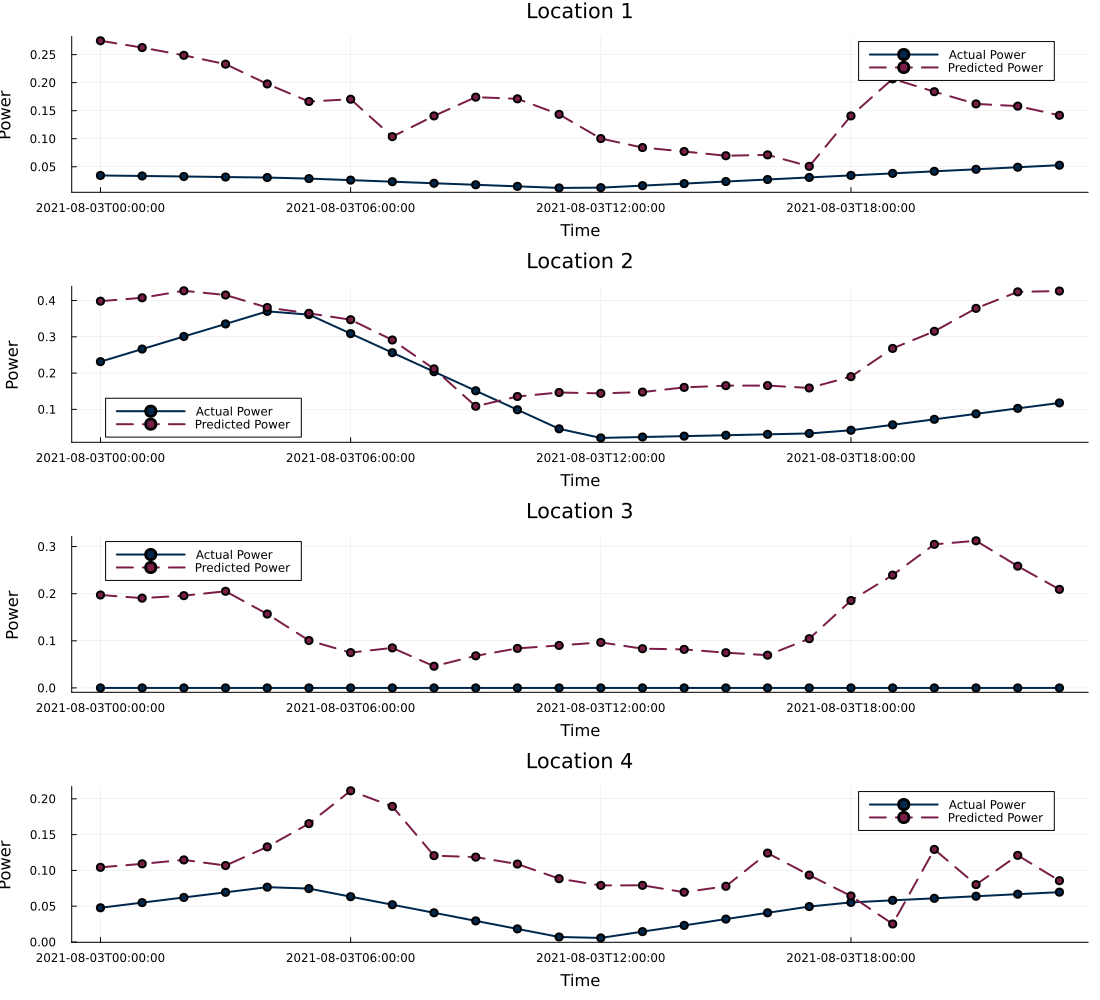

In [60]:
using CSV
using DataFrames
using Dates
using Statistics
using LinearAlgebra
using Random
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and combine data from all four locations
location_data = DataFrame[]

for loc in 1:4
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID = fill(loc, nrow(df))
    push!(location_data, df)
end

data = vcat(location_data...)
sort!(data, [:Time, :LocationID])

# Extract power and weather data
t = Float64.(data.Power)
x = Float64.(data.windspeed_10m) ./ 10.0
z = Float64.(data.windspeed_100m) ./ 10.0
windgust = Float64.(data.windgusts_10m) ./ 10.0

time = data.Time
dates = Date.(time)
location_id = data.LocationID
unique_dates = sort(unique(dates))

# Find eligible validation days with 24 consecutive hourly observations
# at every included location
eligible_dates = Date[]

for d in unique_dates
    day_idx = findall(dates .== d)

    valid_day = true

    for loc in 1:4
        loc_day_idx = [i for i in day_idx if location_id[i] == loc]

        if length(loc_day_idx) != 24
            valid_day = false
            break
        end

        if !all(
            time[loc_day_idx[j]] - time[loc_day_idx[j-1]] == Hour(1)
            for j in 2:length(loc_day_idx)
        )
            valid_day = false
            break
        end

        # Require at least one earlier observation at this location
        earlier_idx = findall(location_id .== loc .&& time .< time[first(loc_day_idx)])

        if isempty(earlier_idx)
            valid_day = false
            break
        end
    end

    if valid_day
        push!(eligible_dates, d)
    end
end

if isempty(eligible_dates)
    error("No date has a complete 24-hour validation period for all four locations.")
end

# Randomly select a validation date
forecast_date = rand(eligible_dates)

# Select validation observations for all locations on that date
forecast_idx = findall(dates .== forecast_date)

# Training data must be earlier than the validation date
train_idx = [
    i for i in 1:length(t)
    if time[i] < DateTime(forecast_date) &&
       isfinite(t[i]) &&
       isfinite(x[i]) &&
       isfinite(z[i]) &&
       isfinite(windgust[i])
]

if length(train_idx) < 10
    error("Not enough valid training observations before the validation date.")
end

# Keep only valid validation observations
forecast_idx = [
    i for i in forecast_idx
    if isfinite(t[i]) &&
       isfinite(x[i]) &&
       isfinite(z[i]) &&
       isfinite(windgust[i])
]

y_train = t[train_idx]
n_train = length(train_idx)

println("Random validation date: ", forecast_date)
println("Training locations: 1, 2, 3, and 4")
println("Validation locations: 1, 2, 3, and 4")
println("Training observations: ", n_train)
println("Validation observations: ", length(forecast_idx))

# RBF model parameters
α = 0.01
iter_max = 25_000
λ = 0.001
reg_type = "l2"

c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

# Gaussian RBF transformation
function rbf(value, centers, gamma)
    return exp.(-((gamma .* abs.(value .- centers)).^2))
end

# Construct RBF feature matrices
function make_rbf_matrix(values, centers, gamma)
    Φ = zeros(length(values), length(centers))

    for i in eachindex(values)
        Φ[i, :] = rbf(values[i], centers, gamma)
    end

    return Φ
end

Φ_10 = make_rbf_matrix(x[train_idx], c, γ)
Φ_100 = make_rbf_matrix(z[train_idx], c, γ)
Φ_gust = make_rbf_matrix(windgust[train_idx], c, γ)

# Initialize model parameters
w_0 = mean(y_train)

w_10 = zeros(num_centers)
w_100 = zeros(num_centers)
w_gust = zeros(num_centers)

# Stochastic gradient descent
for iteration in 1:iter_max

    i = rand(1:n_train)

    ϕ10_i = view(Φ_10, i, :)
    ϕ100_i = view(Φ_100, i, :)
    ϕgust_i = view(Φ_gust, i, :)

    # Prediction using weather features only
    y_hat = w_0 +
            dot(w_10, ϕ10_i) +
            dot(w_100, ϕ100_i) +
            dot(w_gust, ϕgust_i)

    error = y_hat - y_train[i]

    # Calculate gradients
    grad_10 = error .* ϕ10_i
    grad_100 = error .* ϕ100_i
    grad_gust = error .* ϕgust_i

    # Update parameters
    w_0 -= α * error

    if reg_type == "l2"
        w_10 .-= α .* (grad_10 .+ λ .* w_10)
        w_100 .-= α .* (grad_100 .+ λ .* w_100)
        w_gust .-= α .* (grad_gust .+ λ .* w_gust)

    elseif reg_type == "l1"
        w_10 .-= α .* grad_10
        w_100 .-= α .* grad_100
        w_gust .-= α .* grad_gust

        w_10 .= sign.(w_10) .* max.(0, abs.(w_10) .- α * λ)
        w_100 .= sign.(w_100) .* max.(0, abs.(w_100) .- α * λ)
        w_gust .= sign.(w_gust) .* max.(0, abs.(w_gust) .- α * λ)
    end
end

# Build validation weather features
Φ_10_val = make_rbf_matrix(x[forecast_idx], c, γ)
Φ_100_val = make_rbf_matrix(z[forecast_idx], c, γ)
Φ_gust_val = make_rbf_matrix(windgust[forecast_idx], c, γ)

# Predict validation observations independently
predicted_power = zeros(length(forecast_idx))

for i in eachindex(forecast_idx)
    predicted_power[i] = w_0 +
        dot(w_10, view(Φ_10_val, i, :)) +
        dot(w_100, view(Φ_100_val, i, :)) +
        dot(w_gust, view(Φ_gust_val, i, :))
end

# Actual validation power and metadata
actual_power = t[forecast_idx]
forecast_time = time[forecast_idx]
forecast_location = location_id[forecast_idx]

# Calculate performance metrics
valid_eval = [
    i for i in eachindex(actual_power)
    if isfinite(actual_power[i]) && isfinite(predicted_power[i])
]

if isempty(valid_eval)
    error("No valid observations available for validation metrics.")
end

errors = predicted_power[valid_eval] .- actual_power[valid_eval]
RMSE = sqrt(mean(errors .^ 2))
MAE = mean(abs.(errors))

println("\n========== MODEL PERFORMANCE ==========")
println("Validation date: ", forecast_date)
println("Training observations: ", n_train)
println("Validation observations: ", length(valid_eval))
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("Norm w_10 = ", norm(w_10))
println("Norm w_100 = ", norm(w_100))
println("Norm w_gust = ", norm(w_gust))
println("=======================================")

# Store validation results
results = DataFrame(
    Time = forecast_time,
    LocationID = forecast_location,
    ActualPower = actual_power,
    PredictedPower = predicted_power
)

sort!(results, [:LocationID, :Time])
display(results)

# Plot actual versus predicted power separately for each location
p = plot(
    layout = (4, 1),
    size = (1100, 1000),
    xlabel = "Time",
    ylabel = "Power",
    legend = :best
)

for loc in 1:4
    loc_positions = findall(forecast_location .== loc)

    plot!(
        p[loc],
        forecast_time[loc_positions],
        actual_power[loc_positions],
        label = "Actual Power",
        color = blue,
        linewidth = 2,
        marker = :circle,
        title = "Location $loc"
    )

    plot!(
        p[loc],
        forecast_time[loc_positions],
        predicted_power[loc_positions],
        label = "Predicted Power",
        color = purple,
        linestyle = :dash,
        linewidth = 2,
        marker = :circle
    )
end

display(p)

Validation day: 2019-06-11
Training observations: 21359
Validation observations: 24
Training RMSE: 0.033780882454574404
Validation RMSE: 0.16105597858701426
Validation MAE: 0.14444013210766526
Learned standardized lag coefficient: 0.2725998511549296


Row,Time,ActualPower,PredictedPower
,DateTime,Float64,Float64
1,2019-06-11T00:00:00,0.6106,0.656908
2,2019-06-11T01:00:00,0.5636,0.658838
3,2019-06-11T02:00:00,0.5167,0.657541
4,2019-06-11T03:00:00,0.4698,0.649482
5,2019-06-11T04:00:00,0.4228,0.641792
6,2019-06-11T05:00:00,0.3897,0.632496
7,2019-06-11T06:00:00,0.3703,0.613619
8,2019-06-11T07:00:00,0.3509,0.584642
9,2019-06-11T08:00:00,0.3316,0.555101


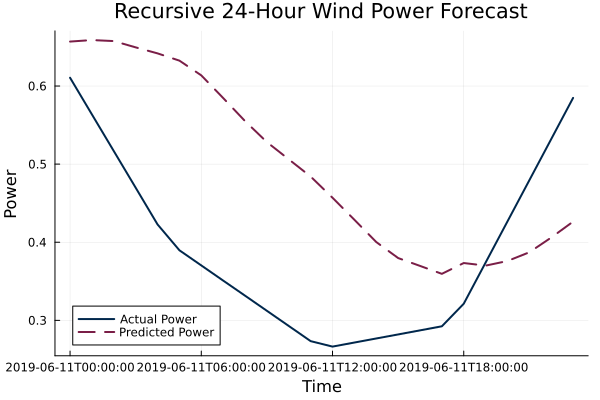

In [57]:
using CSV
using DataFrames
using Dates
using Statistics
using Random
using LinearAlgebra
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and sort the data
data = CSV.read("Location1.csv", DataFrame)
data.Time = DateTime.(data.Time)
sort!(data, :Time)

time = data.Time
t = Float64.(data.Power)

# Weather features
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0

# RBF parameters
c = collect(0.0:0.05:1.1)
gamma = 5.0
num_centers = length(c)

# Training parameters
alpha = 0.01
iter_max = 25_000
lambda = 0.001
reg_type = "l2"

# Construct RBF feature matrices
Phi10 = [exp(-((gamma * abs(x10[i] - cj))^2))
         for i in 1:length(t), cj in c]

Phi100 = [exp(-((gamma * abs(x100[i] - cj))^2))
          for i in 1:length(t), cj in c]

PhiGust = [exp(-((gamma * abs(xgust[i] - cj))^2))
           for i in 1:length(t), cj in c]

# Find complete days containing 24 consecutive hourly observations
eligible_days = Date[]

for d in unique(Date.(time))
    day_idx = findall(Date.(time) .== d)

    if length(day_idx) != 24
        continue
    end

    start_idx = first(day_idx)
    end_idx = last(day_idx)

    # Require the day to begin at midnight
    if Dates.hour(time[start_idx]) != 0 ||
        Dates.minute(time[start_idx]) != 0
            continue
    end

    # Require consecutive hourly observations
    if all(time[i] - time[i-1] == Hour(1)
           for i in (start_idx+1):end_idx) &&
       start_idx > 24 &&
       time[start_idx] - time[start_idx-1] == Hour(1)

        push!(eligible_days, d)
    end
end

if isempty(eligible_days)
    error("No eligible complete 24-hour validation day was found.")
end

# Randomly select a validation day
validation_day = rand(eligible_days)
validation_idx = findall(Date.(time) .== validation_day)

start_idx = first(validation_idx)
end_idx = last(validation_idx)

# Train exclusively on observations before the validation day
train_idx = [
    i for i in 2:(start_idx-1)
    if time[i] - time[i-1] == Hour(1)
]

if length(train_idx) < 24
    error("Not enough valid training observations before the validation day.")
end

println("Validation day: ", validation_day)
println("Training observations: ", length(train_idx))
println("Validation observations: ", length(validation_idx))

# Standardize the lag using training data only
lag_train = t[train_idx .- 1]
lag_mean = mean(lag_train)
lag_std = std(lag_train)

if !isfinite(lag_std) || lag_std <= eps(Float64)
    lag_std = 1.0
end

lag_z = (lag_train .- lag_mean) ./ lag_std

# Initialize model parameters
w0 = mean(t[train_idx])
w10 = zeros(num_centers)
w100 = zeros(num_centers)
wgust = zeros(num_centers)
wlag = 0.0

# Train using stochastic gradient descent
for iteration in 1:iter_max

    # Randomly sample one training observation
    i = rand(train_idx)

    # Standardized previous-hour actual power
    previous_power_z = (t[i-1] - lag_mean) / lag_std

    # Prediction
    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    error = prediction - t[i]

    # Update intercept
    w0 -= alpha * error

    # Update weather RBF weights
    if reg_type == "l2"
        w10 .-= alpha .* (error .* Phi10[i, :] .+ lambda .* w10)
        w100 .-= alpha .* (error .* Phi100[i, :] .+ lambda .* w100)
        wgust .-= alpha .* (error .* PhiGust[i, :] .+ lambda .* wgust)

        # Update standardized lag coefficient
        wlag -= alpha * (error * previous_power_z + lambda * wlag)
    else
        w10 .-= alpha .* (error .* Phi10[i, :])
        w100 .-= alpha .* (error .* Phi100[i, :])
        wgust .-= alpha .* (error .* PhiGust[i, :])

        wlag -= alpha * error * previous_power_z
    end
end

# Evaluate training predictions using actual previous-hour power
train_predictions = Float64[]

for i in train_idx
    previous_power_z = (t[i-1] - lag_mean) / lag_std

    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    push!(train_predictions, prediction)
end

train_rmse = sqrt(mean((train_predictions .- t[train_idx]).^2))

# Recursive 24-hour forecast
# Hour 1 uses the last actual training observation.
# Each later hour uses the previous hour's prediction.
predictions = Float64[]
previous_power = t[start_idx-1]

for i in start_idx:end_idx

    previous_power_z = (previous_power - lag_mean) / lag_std

    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    push!(predictions, prediction)

    # Feed the prediction into the next hour
    previous_power = prediction
end

# Validation metrics
actual = t[validation_idx]

validation_rmse = sqrt(mean((predictions .- actual).^2))
validation_mae = mean(abs.(predictions .- actual))

println("Training RMSE: ", train_rmse)
println("Validation RMSE: ", validation_rmse)
println("Validation MAE: ", validation_mae)
println("Learned standardized lag coefficient: ", wlag)

# Store validation results
results = DataFrame(
    Time = time[validation_idx],
    ActualPower = actual,
    PredictedPower = predictions
)

display(results)

# Plot actual versus predicted power
plot(
    time[validation_idx],
    actual,
    label = "Actual Power",
    color = blue,
    linewidth = 2,
    xlabel = "Time",
    ylabel = "Power",
    title = "Recursive 24-Hour Wind Power Forecast",
    legend = :best
)

plot!(
    time[validation_idx],
    predictions,
    label = "Predicted Power",
    color = purple,
    linewidth = 2,
    linestyle = :dash
)

Validation date: 2017-07-28
Training observations: 19868
Validation observations: 96
Training RMSE: 0.03336107470377972
Validation RMSE: 0.2023522065391786
Validation MAE: 0.12398220467187548
Learned standardized lag coefficient: 0.24671070230340128


Row,Time,LocationID,ActualPower,PredictedPower
,DateTime,Int64,Float64,Float64
1,2017-07-28T00:00:00,1,0.4276,0.395138
2,2017-07-28T01:00:00,1,0.4547,0.393669
3,2017-07-28T02:00:00,1,0.4819,0.392289
4,2017-07-28T03:00:00,1,0.509,0.38978
5,2017-07-28T04:00:00,1,0.5361,0.386076
6,2017-07-28T05:00:00,1,0.5607,0.376816
7,2017-07-28T06:00:00,1,0.5826,0.362402
8,2017-07-28T07:00:00,1,0.6046,0.343707
9,2017-07-28T08:00:00,1,0.6266,0.331754


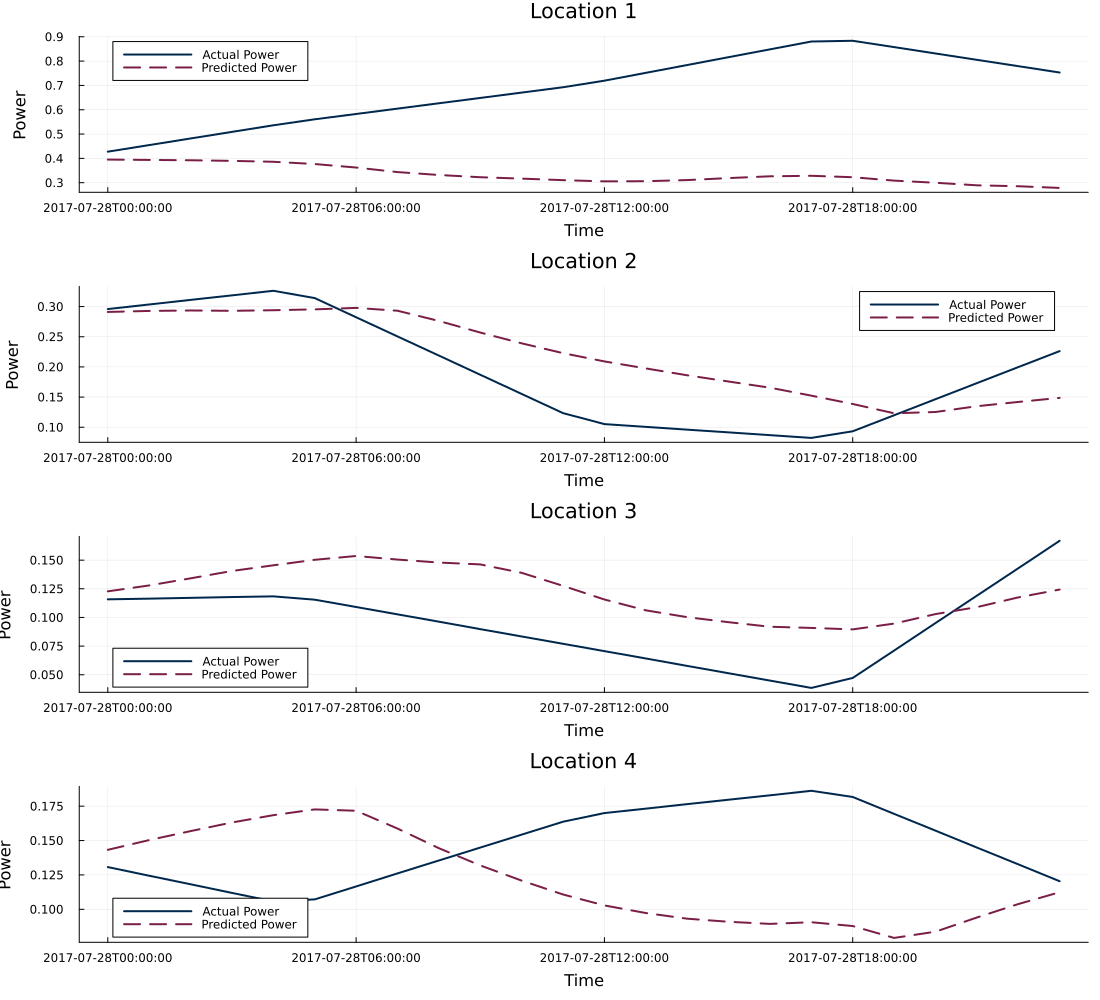

In [61]:
using CSV
using DataFrames
using Dates
using Statistics
using Random
using LinearAlgebra
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

# Load and combine all four locations
location_data = DataFrame[]

for loc in 1:4
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID = fill(loc, nrow(df))
    push!(location_data, df)
end

data = vcat(location_data...)
sort!(data, [:LocationID, :Time])

time = data.Time
t = Float64.(data.Power)
location_id = data.LocationID
n = length(t)

# Weather features
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0

# Find the previous-hour observation within the same location
prev_idx = zeros(Int, n)

for loc in 1:4
    loc_idx = findall(location_id .== loc)

    for j in 2:length(loc_idx)
        i = loc_idx[j]
        previous_i = loc_idx[j-1]

        if time[i] - time[previous_i] == Hour(1)
            prev_idx[i] = previous_i
        end
    end
end

# RBF parameters
c = collect(0.0:0.05:1.1)
gamma = 5.0
num_centers = length(c)

# Training parameters
alpha = 0.01
iter_max = 25_000
lambda = 0.001
reg_type = "l2"

# Construct RBF feature matrices
Phi10 = [exp(-((gamma * abs(x10[i] - cj))^2))
         for i in 1:n, cj in c]

Phi100 = [exp(-((gamma * abs(x100[i] - cj))^2))
          for i in 1:n, cj in c]

PhiGust = [exp(-((gamma * abs(xgust[i] - cj))^2))
           for i in 1:n, cj in c]

# Find dates with 24 consecutive hourly observations at all locations
eligible_days = Date[]

for d in sort(unique(Date.(time)))
    valid_day = true

    for loc in 1:4
        day_idx = findall(
            (Date.(time) .== d) .& (location_id .== loc)
        )

        if length(day_idx) != 24
            valid_day = false
            break
        end

        if !all(
            time[day_idx[j]] - time[day_idx[j-1]] == Hour(1)
            for j in 2:length(day_idx)
        )
            valid_day = false
            break
        end

        first_loc_idx = first(day_idx)

        if prev_idx[first_loc_idx] == 0
            valid_day = false
            break
        end
    end

    if valid_day
        push!(eligible_days, d)
    end
end

if isempty(eligible_days)
    error("No complete 24-hour validation day is available for all four locations.")
end

# Randomly select a validation date
validation_day = rand(eligible_days)

# Select all four locations on the validation date
validation_idx = findall(Date.(time) .== validation_day)

# Train on valid observations strictly before the validation date
train_idx = [
    i for i in 1:n
    if time[i] < DateTime(validation_day) &&
       prev_idx[i] > 0 &&
       isfinite(t[i]) &&
       isfinite(t[prev_idx[i]]) &&
       isfinite(x10[i]) &&
       isfinite(x100[i]) &&
       isfinite(xgust[i])
]

# Keep validation observations with valid weather and power data
validation_idx = [
    i for i in validation_idx
    if isfinite(t[i]) &&
       isfinite(x10[i]) &&
       isfinite(x100[i]) &&
       isfinite(xgust[i])
]

if length(train_idx) < 24
    error("Not enough valid training observations.")
end

if isempty(validation_idx)
    error("No valid validation observations.")
end

println("Validation date: ", validation_day)
println("Training observations: ", length(train_idx))
println("Validation observations: ", length(validation_idx))

# Standardize lagged power using training data only
lag_train = t[prev_idx[train_idx]]
lag_mean = mean(lag_train)
lag_std = std(lag_train)

if !isfinite(lag_std) || lag_std <= eps(Float64)
    lag_std = 1.0
end

# Initialize model parameters
w0 = mean(t[train_idx])
w10 = zeros(num_centers)
w100 = zeros(num_centers)
wgust = zeros(num_centers)
wlag = 0.0

# Train using stochastic gradient descent
for iteration in 1:iter_max
    i = rand(train_idx)

    previous_power_z = (t[prev_idx[i]] - lag_mean) / lag_std

    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    error = prediction - t[i]

    w0 -= alpha * error

    if reg_type == "l2"
        w10 .-= alpha .* (error .* Phi10[i, :] .+ lambda .* w10)
        w100 .-= alpha .* (error .* Phi100[i, :] .+ lambda .* w100)
        wgust .-= alpha .* (error .* PhiGust[i, :] .+ lambda .* wgust)

        wlag -= alpha * (error * previous_power_z + lambda * wlag)
    else
        w10 .-= alpha .* (error .* Phi10[i, :])
        w100 .-= alpha .* (error .* Phi100[i, :])
        wgust .-= alpha .* (error .* PhiGust[i, :])

        wlag -= alpha * error * previous_power_z
    end
end

# Training predictions using actual previous-hour power
train_predictions = Float64[]

for i in train_idx
    previous_power_z = (t[prev_idx[i]] - lag_mean) / lag_std

    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    push!(train_predictions, prediction)
end

train_rmse = sqrt(mean((train_predictions .- t[train_idx]).^2))

# Recursive 24-hour forecasts, separately for each location
predictions = fill(NaN, length(validation_idx))

for loc in 1:4
    positions = findall(location_id[validation_idx] .== loc)

    if isempty(positions)
        continue
    end

    loc_validation_idx = validation_idx[positions]
    first_validation_idx = first(loc_validation_idx)

    # Use the last actual power observation before this location's forecast
    previous_power = t[prev_idx[first_validation_idx]]

    for pos in positions
        i = validation_idx[pos]

        previous_power_z = (previous_power - lag_mean) / lag_std

        prediction = w0 +
            dot(w10, Phi10[i, :]) +
            dot(w100, Phi100[i, :]) +
            dot(wgust, PhiGust[i, :]) +
            wlag * previous_power_z

        predictions[pos] = prediction

        # Feed this location's prediction into its next hour
        previous_power = prediction
    end
end

# Validation metrics
actual = t[validation_idx]
forecast_time = time[validation_idx]
forecast_location = location_id[validation_idx]

valid_eval = [
    i for i in eachindex(actual)
    if isfinite(actual[i]) && isfinite(predictions[i])
]

if isempty(valid_eval)
    error("No valid observations available for validation metrics.")
end

errors = predictions[valid_eval] .- actual[valid_eval]
validation_rmse = sqrt(mean(errors .^ 2))
validation_mae = mean(abs.(errors))

println("Training RMSE: ", train_rmse)
println("Validation RMSE: ", validation_rmse)
println("Validation MAE: ", validation_mae)
println("Learned standardized lag coefficient: ", wlag)

# Store and display validation results
results = DataFrame(
    Time = forecast_time,
    LocationID = forecast_location,
    ActualPower = actual,
    PredictedPower = predictions
)

sort!(results, [:LocationID, :Time])
display(results)

# Plot each location separately
p = plot(
    layout = (4, 1),
    size = (1100, 1000),
    legend = :best
)

for loc in 1:4
    positions = findall(forecast_location .== loc)

    plot!(
        p[loc],
        forecast_time[positions],
        actual[positions],
        label = "Actual Power",
        color = blue,
        linewidth = 2,
        xlabel = "Time",
        ylabel = "Power",
        title = "Location $loc"
    )

    plot!(
        p[loc],
        forecast_time[positions],
        predictions[positions],
        label = "Predicted Power",
        color = purple,
        linewidth = 2,
        linestyle = :dash
    )
end

display(p)

Validation date: 2020-02-24
Training observations: 110204
Validation observations: 96

Training RMSE: 0.03117969392042496
Training MAE: 0.02249778898990535
Validation RMSE: 0.1744137972759891
Validation MAE: 0.1447323141044509
Learned standardized lag coefficient: 0.23845258882993695

Validation errors by hour:


Row,ForecastHour,RMSE,MAE
,Int64,Float64,Float64
1,0,0.0284184,0.0252128
2,1,0.0555135,0.049623
3,2,0.0809962,0.0726956
4,3,0.103265,0.0936856
5,4,0.122279,0.112153
6,5,0.136402,0.123646
7,6,0.153586,0.12906
8,7,0.173099,0.134953
9,8,0.189345,0.156555


Row,Time,LocationID,ActualPower,PredictedPower
,DateTime,Int64,Float64,Float64
1,2020-02-24T00:00:00,1,0.6173,0.655527
2,2020-02-24T01:00:00,1,0.5797,0.65088
3,2020-02-24T02:00:00,1,0.542,0.646157
4,2020-02-24T03:00:00,1,0.5043,0.637722
5,2020-02-24T04:00:00,1,0.4666,0.625936
6,2020-02-24T05:00:00,1,0.4194,0.61218
7,2020-02-24T06:00:00,1,0.3624,0.598112
8,2020-02-24T07:00:00,1,0.3055,0.578109
9,2020-02-24T08:00:00,1,0.2486,0.546545


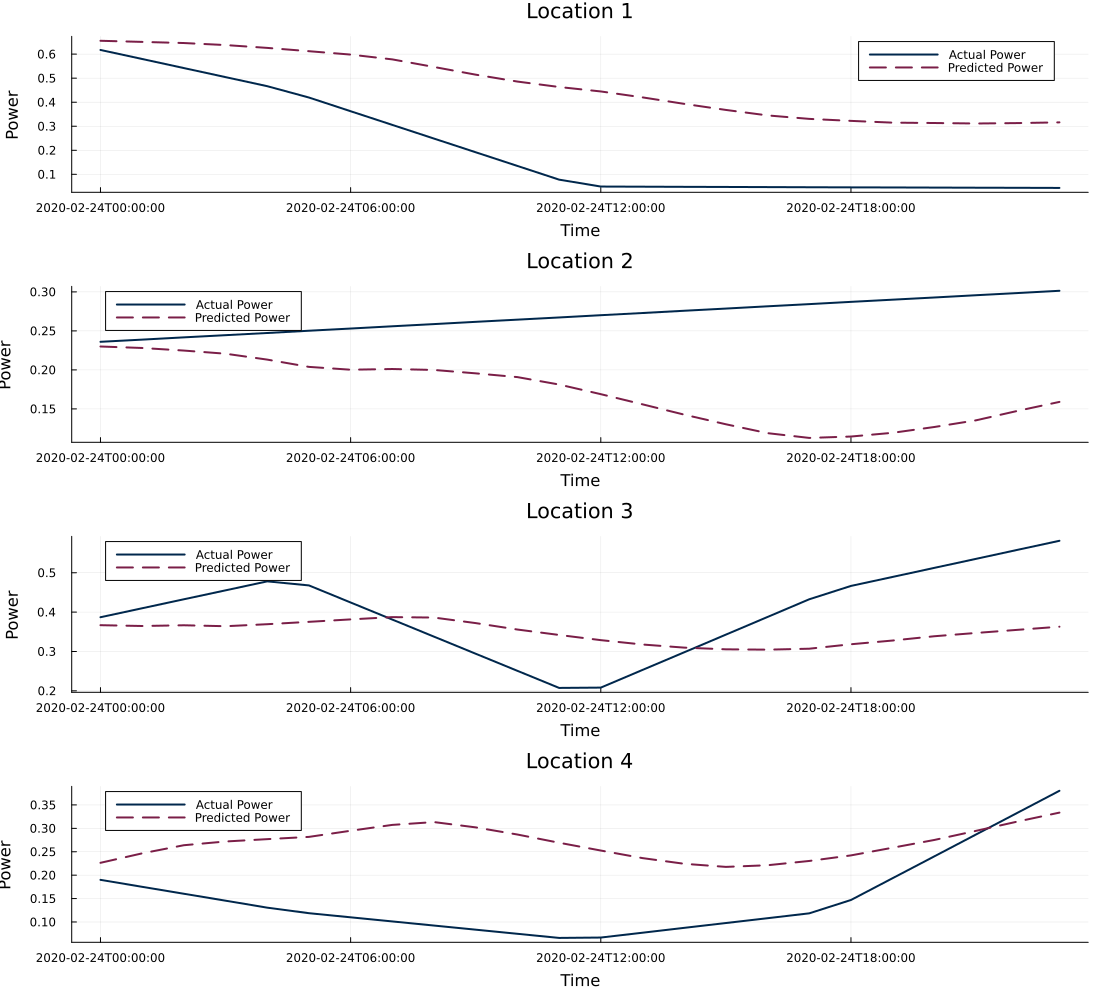

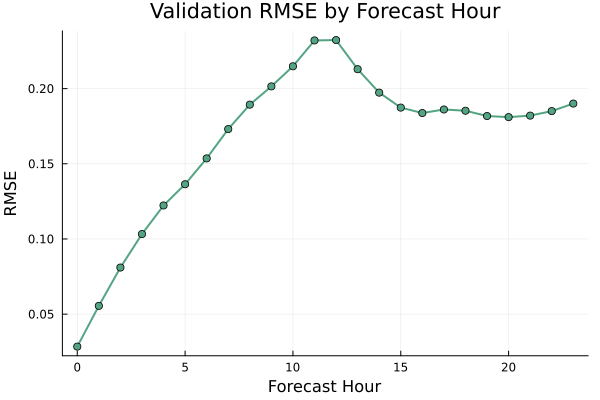

In [78]:

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

Random.seed!(42)

# Load and combine all four locations
location_data = DataFrame[]

for loc in 1:4
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID = fill(loc, nrow(df))
    push!(location_data, df)
end

data = vcat(location_data...)
sort!(data, [:LocationID, :Time])

time = data.Time
t = Float64.(data.Power)
location_id = data.LocationID
n = length(t)

# Weather features
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0

# Find the previous-hour observation within the same location
prev_idx = zeros(Int, n)

for loc in 1:4
    loc_idx = findall(location_id .== loc)

    for j in 2:length(loc_idx)
        i = loc_idx[j]
        previous_i = loc_idx[j-1]

        if time[i] - time[previous_i] == Hour(1)
            prev_idx[i] = previous_i
        end
    end
end

# RBF parameters with separate centers for each weather feature
c10 = collect(0.0:0.05:1.1)
c100 = collect(0.0:0.05:1.5)
cgust = collect(0.0:0.05:2.1)

gamma = 10

num_centers10 = length(c10)
num_centers100 = length(c100)
num_centersgust = length(cgust)

# Training parameters
alpha = 0.0005
iter_max = 25_000
lambda = 0.01
reg_type = "l2"

# Construct RBF feature matrices using the new centers
Phi10 = [
    exp(-gamma * (x10[i] - cj)^2)
    for i in 1:n, cj in c10
]

Phi100 = [
    exp(-gamma * (x100[i] - cj)^2)
    for i in 1:n, cj in c100
]

PhiGust = [
    exp(-gamma * (xgust[i] - cj)^2)
    for i in 1:n, cj in cgust
]

# Initialize model parameters
w0 = mean(t[train_idx])
w10 = zeros(num_centers10)
w100 = zeros(num_centers100)
wgust = zeros(num_centersgust)
wlag = 0.0

# Find dates with 24 consecutive hourly observations at all locations
eligible_days = Date[]

for d in sort(unique(Date.(time)))
    valid_day = true

    for loc in 1:4
        day_idx = findall(
            (Date.(time) .== d) .& (location_id .== loc)
        )

        if length(day_idx) != 24
            valid_day = false
            break
        end

        if !all(
            time[day_idx[j]] - time[day_idx[j-1]] == Hour(1)
            for j in 2:length(day_idx)
        )
            valid_day = false
            break
        end

        if prev_idx[first(day_idx)] == 0
            valid_day = false
            break
        end
    end

    if valid_day
        push!(eligible_days, d)
    end
end

if isempty(eligible_days)
    error("No complete 24-hour validation day is available for all four locations.")
end

# Randomly select a validation day
validation_day = rand(eligible_days)

# Select the complete validation day
validation_idx = findall(Date.(time) .== validation_day)

# Train strictly before the validation day
train_idx = [
    i for i in 1:n
    if time[i] < DateTime(validation_day) &&
       prev_idx[i] > 0 &&
       isfinite(t[i]) &&
       isfinite(t[prev_idx[i]]) &&
       isfinite(x10[i]) &&
       isfinite(x100[i]) &&
       isfinite(xgust[i]) &&
       isfinite(x10[prev_idx[i]]) &&
       isfinite(x100[prev_idx[i]]) &&
       isfinite(xgust[prev_idx[i]])
]

# Keep validation observations with valid features and power
validation_idx = [
    i for i in validation_idx
    if isfinite(t[i]) &&
       isfinite(x10[i]) &&
       isfinite(x100[i]) &&
       isfinite(xgust[i])
]

if length(train_idx) < 24
    error("Not enough valid training observations.")
end

if isempty(validation_idx)
    error("No valid validation observations.")
end

println("Validation date: ", validation_day)
println("Training observations: ", length(train_idx))
println("Validation observations: ", length(validation_idx))

# Standardize lagged power using training data only
lag_train = t[prev_idx[train_idx]]
lag_mean = mean(lag_train)
lag_std = std(lag_train)

if !isfinite(lag_std) || lag_std <= eps(Float64)
    lag_std = 1.0
end

# Train using stochastic gradient descent
# Training uses actual previous-hour power measurements
for iteration in 1:iter_max
    i = rand(train_idx)

    previous_power_z = (t[prev_idx[i]] - lag_mean) / lag_std

    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    error = prediction - t[i]

    w0 -= alpha * error

    if reg_type == "l2"
        w10 .-= alpha .* (error .* Phi10[i, :] .+ lambda .* w10)
        w100 .-= alpha .* (error .* Phi100[i, :] .+ lambda .* w100)
        wgust .-= alpha .* (error .* PhiGust[i, :] .+ lambda .* wgust)

        wlag -= alpha * (error * previous_power_z + lambda * wlag)
    else
        w10 .-= alpha .* (error .* Phi10[i, :])
        w100 .-= alpha .* (error .* Phi100[i, :])
        wgust .-= alpha .* (error .* PhiGust[i, :])

        wlag -= alpha * error * previous_power_z
    end
end

# Training predictions using actual previous-hour power
train_predictions = Float64[]

for i in train_idx
    previous_power_z = (t[prev_idx[i]] - lag_mean) / lag_std

    prediction = w0 +
        dot(w10, Phi10[i, :]) +
        dot(w100, Phi100[i, :]) +
        dot(wgust, PhiGust[i, :]) +
        wlag * previous_power_z

    push!(train_predictions, prediction)
end

train_rmse = sqrt(mean((train_predictions .- t[train_idx]).^2))
train_mae = mean(abs.(train_predictions .- t[train_idx]))

# Recursive 24-hour forecasts for each location
predictions = fill(NaN, length(validation_idx))

for loc in 1:4
    positions = findall(location_id[validation_idx] .== loc)

    if isempty(positions)
        continue
    end

    loc_validation_idx = validation_idx[positions]

    # Ensure validation observations are in chronological order
    sort!(loc_validation_idx, by=i -> time[i])

    first_validation_idx = first(loc_validation_idx)

    # Start with the last actual measurement before the forecast day
    previous_power = t[prev_idx[first_validation_idx]]

    for i in loc_validation_idx
        pos = findfirst(==(i), validation_idx)

        previous_power_z = (previous_power - lag_mean) / lag_std

        prediction = w0 +
            dot(w10, Phi10[i, :]) +
            dot(w100, Phi100[i, :]) +
            dot(wgust, PhiGust[i, :]) +
            wlag * previous_power_z

        predictions[pos] = prediction

        # Feed this prediction into the next hour
        previous_power = prediction
    end
end

# Validation metrics
actual = t[validation_idx]
forecast_time = time[validation_idx]
forecast_location = location_id[validation_idx]

valid_eval = [
    i for i in eachindex(actual)
    if isfinite(actual[i]) && isfinite(predictions[i])
]

if isempty(valid_eval)
    error("No valid observations available for validation metrics.")
end

errors = predictions[valid_eval] .- actual[valid_eval]

validation_rmse = sqrt(mean(errors .^ 2))
validation_mae = mean(abs.(errors))

println("\nTraining RMSE: ", train_rmse)
println("Training MAE: ", train_mae)
println("Validation RMSE: ", validation_rmse)
println("Validation MAE: ", validation_mae)
println("Learned standardized lag coefficient: ", wlag)

# Calculate validation error by forecast hour
hourly_errors = DataFrame(
    ForecastHour = Int[],
    RMSE = Float64[],
    MAE = Float64[]
)

for h in 0:23
    hour_positions = [
        i for i in valid_eval
        if Dates.hour(forecast_time[i]) == h
    ]

    if !isempty(hour_positions)
        hour_error = predictions[hour_positions] .- actual[hour_positions]

        push!(hourly_errors, (
            h,
            sqrt(mean(hour_error .^ 2)),
            mean(abs.(hour_error))
        ))
    end
end

println("\nValidation errors by hour:")
display(hourly_errors)

# Store and display validation results
results = DataFrame(
    Time = forecast_time,
    LocationID = forecast_location,
    ActualPower = actual,
    PredictedPower = predictions
)

sort!(results, [:LocationID, :Time])
display(results)

# Plot each location separately
p = plot(
    layout = (4, 1),
    size = (1100, 1000),
    legend = :best
)

for loc in 1:4
    positions = findall(forecast_location .== loc)

    plot!(
        p[loc],
        forecast_time[positions],
        actual[positions],
        label = "Actual Power",
        color = blue,
        linewidth = 2,
        xlabel = "Time",
        ylabel = "Power",
        title = "Location $loc"
    )

    plot!(
        p[loc],
        forecast_time[positions],
        predictions[positions],
        label = "Predicted Power",
        color = purple,
        linewidth = 2,
        linestyle = :dash
    )
end

display(p)

# Plot validation RMSE by forecast hour
p_hourly = plot(
    hourly_errors.ForecastHour,
    hourly_errors.RMSE,
    marker = :circle,
    color = mygreen,
    linewidth = 2,
    xlabel = "Forecast Hour",
    ylabel = "RMSE",
    title = "Validation RMSE by Forecast Hour",
    legend = false
)

display(p_hourly)

10 m wind centers: 23
100 m wind centers: 31
Gust centers: 43

Validation dates:
2018-01-27
2018-03-24
2018-06-07
2018-10-10
2018-10-13
2019-02-12
2019-10-14
2019-11-24
2020-03-25
2021-02-26
2021-05-07
2021-10-10
2021-10-27
2021-11-09

Test date: 2021-11-10

Training observations: 37436
Validation days: 14
Validation observations: 1344
Test observations: 96

Total combinations: 120

Processing gamma = 0.5
Combination 1/120 | λ=0.0001 | α=0.0001 | γ=0.5 | Train RMSE=0.05631 | 14-day Val RMSE=0.1937 | Test RMSE=0.22682
Combination 2/120 | λ=0.001 | α=0.0001 | γ=0.5 | Train RMSE=0.05637 | 14-day Val RMSE=0.19365 | Test RMSE=0.22683
Combination 3/120 | λ=0.01 | α=0.0001 | γ=0.5 | Train RMSE=0.05692 | 14-day Val RMSE=0.19319 | Test RMSE=0.22694
Combination 4/120 | λ=0.1 | α=0.0001 | γ=0.5 | Train RMSE=0.06309 | 14-day Val RMSE=0.1913 | Test RMSE=0.22937
Combination 5/120 | λ=0.0001 | α=0.0005 | γ=0.5 | Train RMSE=0.03179 | 14-day Val RMSE=0.18455 | Test RMSE=0.21018
Combination 6/120 | λ=0.

Row,Lambda,Alpha,Gamma,TrainingRMSE,ValidationRMSE,TestRMSE
,Float64,Float64,Float64,Float64,Float64,Float64
1,0.01,0.0005,10.0,0.0320623,0.175929,0.190781
2,0.01,0.0005,5.0,0.0320527,0.176055,0.194458
3,0.01,0.01,5.0,0.0318145,0.176244,0.20891
4,0.01,0.01,10.0,0.0318666,0.176257,0.206633
5,0.01,0.001,10.0,0.0319284,0.17665,0.194371
6,0.01,0.005,5.0,0.0318003,0.176736,0.195371
7,0.01,0.0005,20.0,0.0320828,0.176888,0.18907
8,0.01,0.001,5.0,0.0319139,0.176911,0.196023
9,0.01,0.01,20.0,0.0318608,0.177063,0.198721


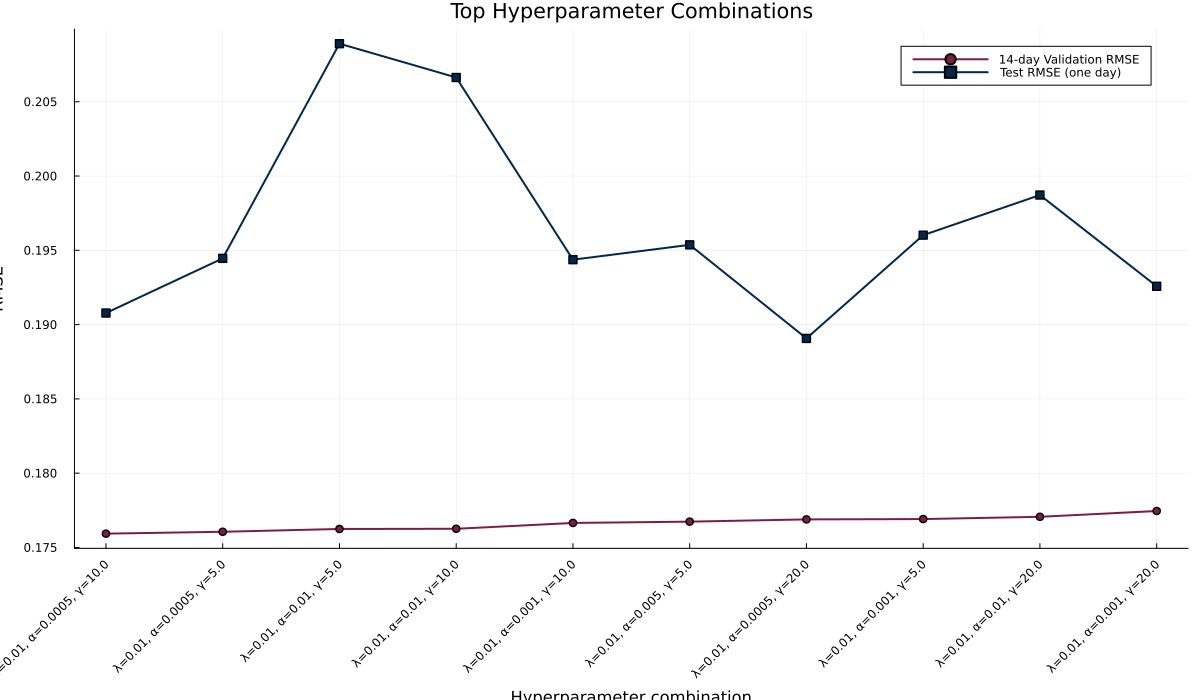

In [77]:


using CSV
using DataFrames
using Dates
using Statistics
using Random
using LinearAlgebra
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

Random.seed!(42)

# ------------------------------------------------------------
# 1. Load and combine all four locations
# ------------------------------------------------------------

location_data = DataFrame[]

for loc in 1:4
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID = fill(loc, nrow(df))
    push!(location_data, df)
end

data = vcat(location_data...)
sort!(data, [:LocationID, :Time])

time = data.Time
dates = Date.(time)
t = Float64.(data.Power)
location_id = data.LocationID
n = length(t)

# Weather features
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0

# ------------------------------------------------------------
# 2. Find previous-hour observations within each location
# ------------------------------------------------------------

prev_idx = zeros(Int, n)

for loc in 1:4
    loc_idx = findall(location_id .== loc)

    for j in 2:length(loc_idx)
        i = loc_idx[j]
        previous_i = loc_idx[j-1]

        if time[i] - time[previous_i] == Hour(1)
            prev_idx[i] = previous_i
        end
    end
end

# ------------------------------------------------------------
# 3. Define separate RBF centers for each weather feature
# ------------------------------------------------------------

c10 = collect(0.0:0.05:1.1)
c100 = collect(0.0:0.05:1.5)
cgust = collect(0.0:0.05:2.1)

num10 = length(c10)
num100 = length(c100)
numgust = length(cgust)

println("10 m wind centers: ", num10)
println("100 m wind centers: ", num100)
println("Gust centers: ", numgust)

# ------------------------------------------------------------
# 4. Find complete eligible 24-hour days
# ------------------------------------------------------------

eligible_days = Date[]

for d in sort(unique(dates))
    valid_day = true

    for loc in 1:4
        day_idx = findall(
            (dates .== d) .& (location_id .== loc)
        )

        if length(day_idx) != 24
            valid_day = false
            break
        end

        sort!(day_idx, by=i -> time[i])

        if !all(
            time[day_idx[j]] - time[day_idx[j-1]] == Hour(1)
            for j in 2:24
        )
            valid_day = false
            break
        end

        if any(
            !isfinite(t[i]) ||
            !isfinite(x10[i]) ||
            !isfinite(x100[i]) ||
            !isfinite(xgust[i]) ||
            prev_idx[i] == 0 ||
            !isfinite(t[prev_idx[i]])
            for i in day_idx
        )
            valid_day = false
            break
        end

        if time[prev_idx[first(day_idx)]] !=
           DateTime(d) - Hour(1)
            valid_day = false
            break
        end
    end

    if valid_day
        push!(eligible_days, d)
    end
end

validation_days_count = 14

if length(eligible_days) < validation_days_count + 1
    error(
        "At least 15 eligible complete days are required " *
        "for 14 validation days and one later test day."
    )
end

# ------------------------------------------------------------
# 5. Randomly select 14 validation days and a later test day
# ------------------------------------------------------------

# Exclude the final eligible day from validation selection so
# at least one later eligible day remains for testing.
validation_candidates = eligible_days[1:end-1]

validation_days = sort(
    Random.shuffle(validation_candidates)[1:validation_days_count]
)

# Test day must occur after every validation day.
later_test_days = filter(
    d -> d > last(validation_days),
    eligible_days
)

if isempty(later_test_days)
    error("No eligible test day occurs after the validation days.")
end

test_day = rand(later_test_days)

println("\nValidation dates:")
foreach(d -> println(d), validation_days)
println("\nTest date: ", test_day)

validation_day_set = Set(validation_days)

validation_idx = sort(
    findall(d -> d in validation_day_set, dates),
    by = i -> (dates[i], location_id[i], time[i])
)

test_idx = sort(
    findall(dates .== test_day),
    by = i -> (location_id[i], time[i])
)

# Train strictly before the earliest validation day.
# The validation and test dates are excluded from training.
first_validation_day = first(validation_days)

train_idx = [
    i for i in 1:n
    if time[i] < DateTime(first_validation_day) &&
       prev_idx[i] > 0 &&
       isfinite(t[i]) &&
       isfinite(t[prev_idx[i]]) &&
       isfinite(x10[i]) &&
       isfinite(x100[i]) &&
       isfinite(xgust[i])
]

if length(train_idx) < 24
    error("Not enough training observations.")
end

println("\nTraining observations: ", length(train_idx))
println("Validation days: ", length(validation_days))
println("Validation observations: ", length(validation_idx))
println("Test observations: ", length(test_idx))

# ------------------------------------------------------------
# 6. Hyperparameter grids
# ------------------------------------------------------------

lambda_values = [0.0001, 0.001, 0.01, 0.1]
alpha_values = [0.0001, 0.0005, 0.001, 0.005, 0.01]
gamma_values = [0.5, 1.0, 2.0, 5.0, 10.0, 20.0]

iter_max = 25_000
reg_type = "l2"

total_combinations =
    length(lambda_values) *
    length(alpha_values) *
    length(gamma_values)

println("\nTotal combinations: ", total_combinations)

# ------------------------------------------------------------
# 7. Standardize lagged power using training data only
# ------------------------------------------------------------

lag_train = t[prev_idx[train_idx]]
lag_mean = mean(lag_train)
lag_std = std(lag_train)

if !isfinite(lag_std) || lag_std <= eps(Float64)
    lag_std = 1.0
end

# ------------------------------------------------------------
# 8. Fit the RBF model using SGD
# ------------------------------------------------------------

function fit_rbf(
    train_idx,
    Phi10,
    Phi100,
    PhiGust,
    t,
    prev_idx,
    lag_mean,
    lag_std,
    alpha,
    lambda,
    iter_max,
    reg_type
)
    w0 = mean(t[train_idx])
    w10 = zeros(size(Phi10, 2))
    w100 = zeros(size(Phi100, 2))
    wgust = zeros(size(PhiGust, 2))
    wlag = 0.0

    Random.seed!(1234)

    for iteration in 1:iter_max
        i = rand(train_idx)

        previous_power_z =
            (t[prev_idx[i]] - lag_mean) / lag_std

        phi10 = view(Phi10, i, :)
        phi100 = view(Phi100, i, :)
        phiGust = view(PhiGust, i, :)

        prediction = w0 +
            dot(w10, phi10) +
            dot(w100, phi100) +
            dot(wgust, phiGust) +
            wlag * previous_power_z

        err = prediction - t[i]

        w0 -= alpha * err

        if reg_type == "l2"
            w10 .-= alpha .* (err .* phi10 .+ lambda .* w10)
            w100 .-= alpha .* (err .* phi100 .+ lambda .* w100)
            wgust .-= alpha .* (err .* phiGust .+ lambda .* wgust)

            wlag -= alpha * (
                err * previous_power_z + lambda * wlag
            )
        else
            w10 .-= alpha .* (err .* phi10)
            w100 .-= alpha .* (err .* phi100)
            wgust .-= alpha .* (err .* phiGust)

            wlag -= alpha * err * previous_power_z
        end
    end

    return (; w0, w10, w100, wgust, wlag)
end

# ------------------------------------------------------------
# 9. Predict a single observation
# ------------------------------------------------------------

function predict_one(
    i,
    previous_power,
    model,
    Phi10,
    Phi100,
    PhiGust,
    lag_mean,
    lag_std
)
    previous_power_z = (previous_power - lag_mean) / lag_std

    return model.w0 +
        dot(model.w10, view(Phi10, i, :)) +
        dot(model.w100, view(Phi100, i, :)) +
        dot(model.wgust, view(PhiGust, i, :)) +
        model.wlag * previous_power_z
end

# ------------------------------------------------------------
# 10. Recursive forecasts, resetting at the start of each day
# ------------------------------------------------------------

function recursive_forecast(
    day_idx,
    model,
    Phi10,
    Phi100,
    PhiGust,
    t,
    prev_idx,
    location_id,
    time,
    lag_mean,
    lag_std
)
    predictions = fill(NaN, length(day_idx))
    forecast_dates = sort(unique(Date.(time[day_idx])))

    for d in forecast_dates
        for loc in 1:4
            loc_idx = [
                i for i in day_idx
                if location_id[i] == loc && Date(time[i]) == d
            ]

            if isempty(loc_idx)
                continue
            end

            sort!(loc_idx, by=i -> time[i])

            # Seed each location and day with the actual
            # observation immediately before that day.
            previous_power = t[prev_idx[first(loc_idx)]]

            for i in loc_idx
                pos = findfirst(==(i), day_idx)

                prediction = predict_one(
                    i,
                    previous_power,
                    model,
                    Phi10,
                    Phi100,
                    PhiGust,
                    lag_mean,
                    lag_std
                )

                predictions[pos] = prediction

                # Feed the prediction into the next hour.
                previous_power = prediction
            end
        end
    end

    return predictions
end

# ------------------------------------------------------------
# 11. Sweep lambda, alpha, and gamma
# ------------------------------------------------------------

results = DataFrame(
    Lambda = Float64[],
    Alpha = Float64[],
    Gamma = Float64[],
    TrainingRMSE = Float64[],
    ValidationRMSE = Float64[],
    TestRMSE = Float64[]
)

combination = 0

for gamma in gamma_values
    println("\nProcessing gamma = ", gamma)

    Phi10 = [
        exp(-gamma * (x10[i] - cj)^2)
        for i in 1:n, cj in c10
    ]

    Phi100 = [
        exp(-gamma * (x100[i] - cj)^2)
        for i in 1:n, cj in c100
    ]

    PhiGust = [
        exp(-gamma * (xgust[i] - cj)^2)
        for i in 1:n, cj in cgust
    ]

    for alpha in alpha_values
        for lambda in lambda_values
            combination += 1

            model = fit_rbf(
                train_idx,
                Phi10,
                Phi100,
                PhiGust,
                t,
                prev_idx,
                lag_mean,
                lag_std,
                alpha,
                lambda,
                iter_max,
                reg_type
            )

            # Training RMSE uses actual previous-hour power.
            train_predictions = [
                predict_one(
                    i,
                    t[prev_idx[i]],
                    model,
                    Phi10,
                    Phi100,
                    PhiGust,
                    lag_mean,
                    lag_std
                )
                for i in train_idx
            ]

            train_rmse = sqrt(
                mean((train_predictions .- t[train_idx]).^2)
            )

            # Validation RMSE across all 14 days and four locations.
            validation_predictions = recursive_forecast(
                validation_idx,
                model,
                Phi10,
                Phi100,
                PhiGust,
                t,
                prev_idx,
                location_id,
                time,
                lag_mean,
                lag_std
            )

            validation_errors =
                validation_predictions .- t[validation_idx]

            validation_rmse = sqrt(
                mean(validation_errors .^ 2)
            )

            # Test RMSE on one later day across all four locations.
            test_predictions = recursive_forecast(
                test_idx,
                model,
                Phi10,
                Phi100,
                PhiGust,
                t,
                prev_idx,
                location_id,
                time,
                lag_mean,
                lag_std
            )

            test_rmse = sqrt(
                mean((test_predictions .- t[test_idx]).^2)
            )

            push!(results, (
                lambda,
                alpha,
                gamma,
                train_rmse,
                validation_rmse,
                test_rmse
            ))

            println(
                "Combination ", combination, "/", total_combinations,
                " | λ=", lambda,
                " | α=", alpha,
                " | γ=", gamma,
                " | Train RMSE=", round(train_rmse, digits=5),
                " | 14-day Val RMSE=", round(validation_rmse, digits=5),
                " | Test RMSE=", round(test_rmse, digits=5)
            )
        end
    end
end

# ------------------------------------------------------------
# 12. Sort results by 14-day validation RMSE
# ------------------------------------------------------------

sort!(results, :ValidationRMSE)

println("\nBest hyperparameters based on 14-day validation RMSE:")
display(first(results, min(10, nrow(results))))

best = results[1, :]

println("\nBest validation combination:")
println("Lambda: ", best.Lambda)
println("Alpha: ", best.Alpha)
println("Gamma: ", best.Gamma)
println("Training RMSE: ", best.TrainingRMSE)
println("14-day Validation RMSE: ", best.ValidationRMSE)
println("Test RMSE: ", best.TestRMSE)

CSV.write("rbf_hyperparameter_sweep.csv", results)

println("\nAll results saved to rbf_hyperparameter_sweep.csv")

# ------------------------------------------------------------
# 13. Plot validation and test RMSE for the top 10 combinations
# ------------------------------------------------------------

top_n = min(10, nrow(results))
top_results = results[1:top_n, :]

labels = [
    "λ=$(r.Lambda), α=$(r.Alpha), γ=$(r.Gamma)"
    for r in eachrow(top_results)
]

p = plot(
    1:top_n,
    top_results.ValidationRMSE,
    label = "14-day Validation RMSE",
    color = purple,
    marker = :circle,
    linewidth = 2,
    xticks = (1:top_n, labels),
    xrotation = 45,
    size = (1200, 700),
    bottom_margin = 12Plots.mm,
    xlabel = "Hyperparameter combination",
    ylabel = "RMSE",
    title = "Top Hyperparameter Combinations",
    legend = :topright
)

plot!(
    p,
    1:top_n,
    top_results.TestRMSE,
    label = "Test RMSE (one day)",
    color = blue,
    marker = :square,
    linewidth = 2
)

display(p)



Best hyperparameters:
Lambda: 0.0001
Alpha: 0.005
Gamma: 5.0
Training RMSE: 0.03200266997170225
Validation RMSE: 0.18239398500905538
Test RMSE: 0.14236450848729756
Validation days: [Date("2018-01-27"), Date("2018-03-24"), Date("2018-06-07"), Date("2018-10-10"), Date("2018-10-13"), Date("2019-02-12"), Date("2019-10-14"), Date("2019-11-24"), Date("2020-03-25"), Date("2021-02-26"), Date("2021-05-07"), Date("2021-10-10"), Date("2021-10-27"), Date("2021-11-09")]
Test day: 2021-12-31


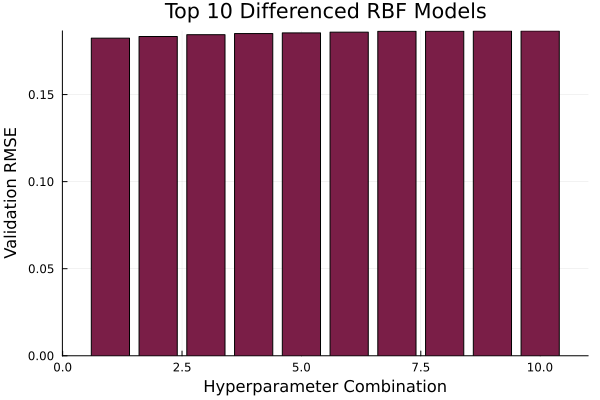

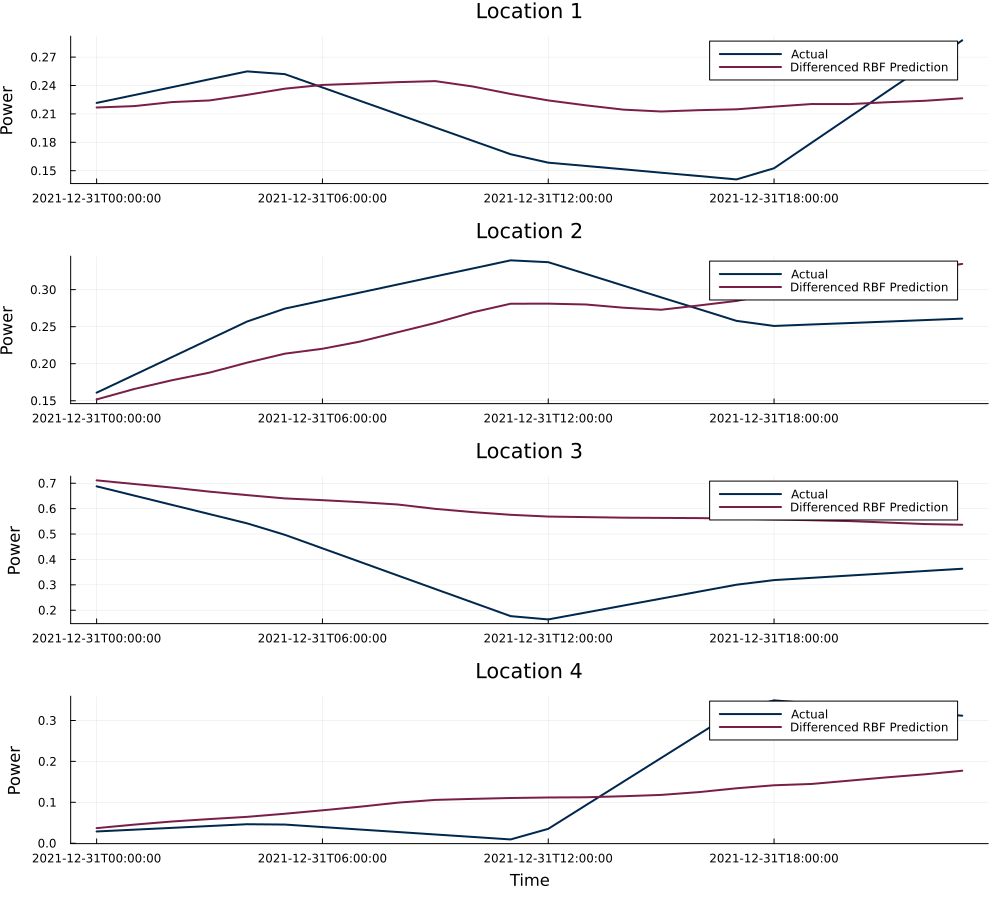

In [80]:
# differenced


using CSV
using DataFrames
using Dates
using Statistics
using Random
using LinearAlgebra
using Plots

purple = RGB(122/256, 30/256, 71/256)
blue = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

Random.seed!(42)

# Load and combine all four locations
data = DataFrame()

for loc in 1:4
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID .= loc
    append!(data, df)
end

sort!(data, [:LocationID, :Time])

time = data.Time
dates = Date.(time)
location_id = data.LocationID
n = nrow(data)

t = Float64.(data.Power)
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0

# Find the preceding hour within the same location
prev_idx = zeros(Int, n)

for i in 2:n
    if location_id[i] == location_id[i-1] &&
       time[i] - time[i-1] == Hour(1)
        prev_idx[i] = i - 1
    end
end

# RBF centers
c10 = collect(0.0:0.05:1.1)
c100 = collect(0.0:0.05:1.5)
cgust = collect(0.0:0.05:2.1)

# Hyperparameter sweep
lambda_values = [0.0001, 0.001, 0.01, 0.1]
alpha_values = [0.0001, 0.0005, 0.001, 0.005, 0.01]
gamma_values = [0.5, 1.0, 2.0, 5.0, 10.0, 20.0]

iter_max = 25_000
reg_type = "l2"

# Identify rows with usable features and a valid preceding hour
valid = [
    prev_idx[i] > 0 &&
    all(isfinite, (t[i], t[prev_idx[i]], x10[i], x100[i], xgust[i]))
    for i in 1:n
]

# Only use complete 24-hour days for validation and testing.
# Each selected day must have 24 consecutive hours at every location.
eligible_days = Date[]

for day in sort(unique(dates))
    day_rows = findall(dates .== day)
    length(day_rows) == 96 || continue

    complete_day = true

    for loc in 1:4
        idx = filter(i -> location_id[i] == loc, day_rows)
        sort!(idx, by=i -> time[i])

        if length(idx) != 24 ||
           any(time[idx[j+1]] - time[idx[j]] != Hour(1) for j in 1:23) ||
           !all(valid[idx])
            complete_day = false
            break
        end
    end

    complete_day && push!(eligible_days, day)
end

length(eligible_days) >= 16 ||
    error("At least 16 eligible complete days are required.")

# Keep the final eligible day as the test day.
# Randomly select 14 earlier days for validation.
test_day = last(eligible_days)
validation_candidates = eligible_days[1:end-1]

validation_days = sort(Random.shuffle(validation_candidates)[1:14])

# Training data must precede the earliest validation day.
first_validation_day = first(validation_days)

train_idx = findall(
    i -> valid[i] && dates[i] < first_validation_day,
    1:n
)

validation_idx = findall(
    i -> dates[i] in validation_days && valid[i],
    1:n
)

test_idx = findall(
    i -> dates[i] == test_day && valid[i],
    1:n
)

length(validation_idx) == 14 * 4 * 24 ||
    error("Validation days must contain 14 complete days across all locations.")

length(test_idx) == 4 * 24 ||
    error("The test day must contain 24 hours for each location.")

isempty(train_idx) && error("No valid training rows were found.")

# Difference target: ΔP(t) = P(t) - P(t-1)
delta_power = fill(NaN, n)

for i in 1:n
    if valid[i]
        delta_power[i] = t[i] - t[prev_idx[i]]
    end
end

# Standardize the differenced target using training data only.
delta_mean = mean(delta_power[train_idx])
delta_std = std(delta_power[train_idx])

delta_std > 0 || error("Training differences have zero standard deviation.")

delta_z = (delta_power .- delta_mean) ./ delta_std

# Standardize the previous-power input using training data only.
lag_values = [t[prev_idx[i]] for i in train_idx]
lag_mean = mean(lag_values)
lag_std = std(lag_values)

lag_std > 0 || error("Training lagged power has zero standard deviation.")

# RBF feature matrices
function rbf_matrix(x, centers, gamma)
    hcat([
        exp.(-gamma .* (x .- center).^2)
        for center in centers
    ]...)
end

function rbf_features(x, centers, gamma)
    exp.(-gamma .* (x .- centers).^2)
end

# Train on standardized power differences.
function fit_rbf(
    train_idx, Phi10, Phi100, PhiGust,
    delta_z, t, prev_idx, lag_mean, lag_std,
    alpha, lambda, iter_max, reg_type
)
    w0 = 0.0
    w10 = zeros(size(Phi10, 2))
    w100 = zeros(size(Phi100, 2))
    wgust = zeros(size(PhiGust, 2))
    wlag = 0.0

    for iteration in 1:iter_max
        i = rand(train_idx)

        p10 = view(Phi10, i, :)
        p100 = view(Phi100, i, :)
        pgust = view(PhiGust, i, :)

        previous_power_z = (t[prev_idx[i]] - lag_mean) / lag_std

        prediction = w0 +
            dot(w10, p10) +
            dot(w100, p100) +
            dot(wgust, pgust) +
            wlag * previous_power_z

        error = prediction - delta_z[i]

        w0 -= alpha * error
        w10 .-= alpha .* (error .* p10)
        w100 .-= alpha .* (error .* p100)
        wgust .-= alpha .* (error .* pgust)
        wlag -= alpha * error * previous_power_z

        if reg_type == "l2"
            w10 .-= alpha * lambda .* w10
            w100 .-= alpha * lambda .* w100
            wgust .-= alpha * lambda .* wgust
            wlag -= alpha * lambda * wlag
        end
    end

    return (
        w0 = w0,
        w10 = w10,
        w100 = w100,
        wgust = wgust,
        wlag = wlag
    )
end

# Predict a power difference and convert it back to power units.
function predict_one(
    i, previous_power, model,
    Phi10, Phi100, PhiGust, lag_mean, lag_std,
    delta_mean, delta_std
)
    previous_power_z = (previous_power - lag_mean) / lag_std

    delta_prediction_z = model.w0 +
        dot(model.w10, view(Phi10, i, :)) +
        dot(model.w100, view(Phi100, i, :)) +
        dot(model.wgust, view(PhiGust, i, :)) +
        model.wlag * previous_power_z

    return delta_mean + delta_std * delta_prediction_z
end

# Recursive forecast:
# first hour starts from actual power in the preceding hour;
# later hours use the previously predicted power.
function recursive_forecast(
    forecast_day, model,
    Phi10, Phi100, PhiGust,
    t, time, dates, location_id, prev_idx,
    lag_mean, lag_std, delta_mean, delta_std
)
    forecast_idx = findall(dates .== forecast_day)
    sort!(forecast_idx, by=i -> (location_id[i], time[i]))

    results = DataFrame(
        Time = DateTime[],
        LocationID = Int[],
        ActualPower = Float64[],
        PredictedPower = Float64[],
        ActualDifference = Float64[],
        PredictedDifference = Float64[]
    )

    for loc in 1:4
        idx = filter(i -> location_id[i] == loc, forecast_idx)
        sort!(idx, by=i -> time[i])

        isempty(idx) && continue

        first_idx = first(idx)
        previous_idx = prev_idx[first_idx]

        previous_idx > 0 ||
            error("Missing preceding-hour power for location $loc on $forecast_day.")

        # Use actual power immediately before the forecast day.
        previous_power = t[previous_idx]

        for i in idx
            predicted_difference = predict_one(
                i, previous_power, model,
                Phi10, Phi100, PhiGust,
                lag_mean, lag_std, delta_mean, delta_std
            )

            predicted_power = previous_power + predicted_difference

            push!(results, (
                time[i],
                location_id[i],
                t[i],
                predicted_power,
                t[i] - t[prev_idx[i]],
                predicted_difference
            ))

            # The next hour uses the prediction, not its actual power.
            previous_power = predicted_power
        end
    end

    sort!(results, [:LocationID, :Time])
    return results
end

# Evaluate one-step training predictions using actual preceding-hour power.
function training_rmse(
    train_idx, model, Phi10, Phi100, PhiGust,
    t, prev_idx, lag_mean, lag_std, delta_mean, delta_std
)
    errors = Float64[]

    for i in train_idx
        predicted_difference = predict_one(
            i, t[prev_idx[i]], model,
            Phi10, Phi100, PhiGust,
            lag_mean, lag_std, delta_mean, delta_std
        )

        predicted_power = t[prev_idx[i]] + predicted_difference
        push!(errors, predicted_power - t[i])
    end

    return sqrt(mean(errors.^2))
end

# Sweep hyperparameters
results = DataFrame(
    Lambda = Float64[],
    Alpha = Float64[],
    Gamma = Float64[],
    TrainingRMSE = Float64[],
    ValidationRMSE = Float64[],
    TestRMSE = Float64[]
)

best_model = nothing
best_gamma = NaN
best_lambda = NaN
best_alpha = NaN
best_validation_rmse = Inf
best_validation_predictions = nothing
best_test_predictions = nothing

for gamma in gamma_values
    Phi10 = rbf_matrix(x10, c10, gamma)
    Phi100 = rbf_matrix(x100, c100, gamma)
    PhiGust = rbf_matrix(xgust, cgust, gamma)

    for lambda in lambda_values
        for alpha in alpha_values
            model = fit_rbf(
                train_idx, Phi10, Phi100, PhiGust,
                delta_z, t, prev_idx, lag_mean, lag_std,
                alpha, lambda, iter_max, reg_type
            )

            train_error = training_rmse(
                train_idx, model, Phi10, Phi100, PhiGust,
                t, prev_idx, lag_mean, lag_std,
                delta_mean, delta_std
            )

            validation_predictions = DataFrame()

            for day in validation_days
                day_predictions = recursive_forecast(
                    day, model,
                    Phi10, Phi100, PhiGust,
                    t, time, dates, location_id, prev_idx,
                    lag_mean, lag_std, delta_mean, delta_std
                )
                append!(validation_predictions, day_predictions)
            end

            validation_rmse = sqrt(mean(
                (validation_predictions.PredictedPower .-
                 validation_predictions.ActualPower).^2
            ))

            test_predictions = recursive_forecast(
                test_day, model,
                Phi10, Phi100, PhiGust,
                t, time, dates, location_id, prev_idx,
                lag_mean, lag_std, delta_mean, delta_std
            )

            test_rmse = sqrt(mean(
                (test_predictions.PredictedPower .-
                 test_predictions.ActualPower).^2
            ))

            push!(results, (
                lambda, alpha, gamma,
                train_error, validation_rmse, test_rmse
            ))

            if validation_rmse < best_validation_rmse
                best_validation_rmse = validation_rmse
                best_model = model
                best_gamma = gamma
                best_lambda = lambda
                best_alpha = alpha
                best_validation_predictions = validation_predictions
                best_test_predictions = test_predictions
            end
        end
    end
end

# Rank and save hyperparameter results
sort!(results, :ValidationRMSE)
CSV.write("rbf_hyperparameter_sweep.csv", results)

println("Best hyperparameters:")
println("Lambda: ", best_lambda)
println("Alpha: ", best_alpha)
println("Gamma: ", best_gamma)
println("Training RMSE: ", results.TrainingRMSE[1])
println("Validation RMSE: ", results.ValidationRMSE[1])
println("Test RMSE: ", results.TestRMSE[1])
println("Validation days: ", validation_days)
println("Test day: ", test_day)

# Save best validation and test forecasts
CSV.write("rbf_differenced_validation_predictions.csv",
          best_validation_predictions)

CSV.write("rbf_differenced_test_predictions.csv",
          best_test_predictions)

# Plot the top 10 hyperparameter combinations
top_results = results[1:min(10, nrow(results)), :]

p1 = bar(
    1:nrow(top_results),
    top_results.ValidationRMSE,
    xlabel = "Hyperparameter Combination",
    ylabel = "Validation RMSE",
    title = "Top 10 Differenced RBF Models",
    color = purple,
    legend = false
)

display(p1)

# Plot the test-day predictions for each location
p2 = plot(
    layout = (4, 1),
    size = (1000, 900),
    legend = :topright
)

for loc in 1:4
    df = filter(row -> row.LocationID == loc, best_test_predictions)
    sort!(df, :Time)

    plot!(
        p2[loc],
        df.Time,
        df.ActualPower,
        label = "Actual",
        color = blue,
        linewidth = 2,
        title = "Location $loc",
        ylabel = "Power"
    )

    plot!(
        p2[loc],
        df.Time,
        df.PredictedPower,
        label = "Differenced RBF Prediction",
        color = purple,
        linewidth = 2
    )
end

xlabel!(p2[4], "Time")
display(p2)


In [ ]:
# Prediction of power change versus previous data point
Random.seed!(42)

# Fixed hyperparameters
lambda = 0.001
alpha = 0.001
gamma = 5.0
iter_max = 25_000
reg_type = "l2"

# Load and combine the three locations
data = DataFrame()

for loc in 1:3
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID .= loc
    append!(data, df)
end

sort!(data, [:LocationID, :Time])

n = nrow(data)
time = data.Time
dates = Date.(time)
location_id = data.LocationID

t = Float64.(data.Power)
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0


131400-element Vector{Float64}:
 0.13999999999999999
 0.44000000000000006
 0.32
 0.16
 0.4
 0.45
 0.47000000000000003
 0.48
 0.58
 0.65
 ⋮
 1.3599999999999999
 1.3900000000000001
 1.41
 1.41
 1.2
 1.23
 1.1800000000000002
 1.1099999999999999
 1.17

In [ ]:

Random.seed!(42)

# Load and combine all four locations
location_data = DataFrame[]
for loc in 1:4
    df = CSV.read("Location$(loc).csv", DataFrame)
    df.Time = DateTime.(df.Time)
    df.LocationID .= loc
    push!(location_data, df)
end

data = vcat(location_data...)
sort!(data, [:LocationID, :Time])

n = nrow(data)
t = Float64.(data.Power)
x10 = Float64.(data.windspeed_10m) ./ 10.0
x100 = Float64.(data.windspeed_100m) ./ 10.0
xgust = Float64.(data.windgusts_10m) ./ 10.0
dates = Date.(data.Time)

# Find the previous consecutive-hour observation within each location
prev_idx = zeros(Int, n)
for i in 2:n
    if data.LocationID[i] == data.LocationID[i-1] &&
       data.Time[i] - data.Time[i-1] == Hour(1)
        prev_idx[i] = i - 1
    end
end

# Calculate first differences
delta_power = fill(NaN, n)
delta_x10 = fill(NaN, n)
delta_x100 = fill(NaN, n)
delta_xgust = fill(NaN, n)

for i in 1:n
    j = prev_idx[i]
    if j > 0
        delta_power[i] = t[i] - t[j]
        delta_x10[i] = x10[i] - x10[j]
        delta_x100[i] = x100[i] - x100[j]
        delta_xgust[i] = xgust[i] - xgust[j]
    end
end

# Construct additional features:
# Current weather differences, previous-hour weather differences,
# previous power difference, and previous power level
raw_extra = fill(NaN, n, 8)

for i in 1:n
    j = prev_idx[i]
    if j > 0 && prev_idx[j] > 0
        raw_extra[i, :] = [
            delta_x10[i], delta_x100[i], delta_xgust[i],
            delta_x10[j], delta_x100[j], delta_xgust[j],
            delta_power[j], t[j]
        ]
    end
end

# Keep observations with sufficient consecutive-hour history
valid = [
    prev_idx[i] > 0 &&
    prev_idx[prev_idx[i]] > 0 &&
    isfinite(t[i]) &&
    isfinite(x10[i]) &&
    isfinite(x100[i]) &&
    isfinite(xgust[i]) &&
    isfinite(delta_power[i]) &&
    all(isfinite, raw_extra[i, :])
    for i in 1:n
]

# Training uses all valid observations from Locations 1–3.
# Location 4 is held out completely for testing.
train_idx = findall(i -> valid[i] && data.LocationID[i] in (1, 2, 3), 1:n)
test_location_idx = findall(i -> valid[i] && data.LocationID[i] == 4, 1:n)

# Select complete 24-hour test days from Location 4
test_days = Date[]

for day in sort(unique(dates[data.LocationID .== 4]))
    idx = findall(i -> data.LocationID[i] == 4 && dates[i] == day, 1:n)
    sort!(idx, by=i -> data.Time[i])

    if length(idx) == 24 &&
       all(valid[idx]) &&
       all(diff(data.Time[idx]) .== Hour(1))
        push!(test_days, day)
    end
end

test_idx = findall(i -> valid[i] && data.LocationID[i] == 4 && dates[i] in test_days, 1:n)

# Standardize features using training data only
delta_mean = mean(delta_power[train_idx])
delta_std = std(delta_power[train_idx])
delta_std = isfinite(delta_std) && delta_std > 0 ? delta_std : 1.0

extra_mean = vec(mean(raw_extra[train_idx, :], dims=1))
extra_std = vec(std(raw_extra[train_idx, :], dims=1))
extra_std[.!isfinite.(extra_std) .| (extra_std .== 0.0)] .= 1.0

delta_z = (delta_power .- delta_mean) ./ delta_std
Zextra = (raw_extra .- extra_mean') ./ extra_std'

# RBF centers and fixed hyperparameters
centers10 = collect(0.0:0.05:1.1)
centers100 = collect(0.0:0.05:1.5)
centersgust = collect(0.0:0.05:2.1)

gamma = 5.0
alpha = 0.001
lambda = 0.001
iter_max = 25_000
reg_type = "l2"

# Construct Gaussian RBF features
rbf_features(x, centers, gamma) = exp.(-gamma .* (x .- centers).^2)

Phi10 = reduce(vcat, [permutedims(rbf_features(x10[i], centers10, gamma)) for i in 1:n])
Phi100 = reduce(vcat, [permutedims(rbf_features(x100[i], centers100, gamma)) for i in 1:n])
PhiGust = reduce(vcat, [permutedims(rbf_features(xgust[i], centersgust, gamma)) for i in 1:n])

# Combine RBF features, standardized extra features, and an intercept
X = hcat(ones(n), Phi10, Phi100, PhiGust, Zextra)

# Fit the model using training observations only
function fit_rbf(train_idx, X, target_z, alpha, lambda, iter_max, reg_type)
    weights = zeros(size(X, 2))
    reg_mask = ones(length(weights))
    reg_mask[1] = 0.0

    for _ in 1:iter_max
        i = rand(train_idx)
        xi = X[i, :]
        error = dot(xi, weights) - target_z[i]
        gradient = 2.0 .* error .* xi

        if reg_type == "l2"
            gradient .+= 2.0 * lambda .* reg_mask .* weights
        end

        weights .-= alpha .* gradient
    end

    return weights
end

weights = fit_rbf(train_idx, X, delta_z, alpha, lambda, iter_max, reg_type)

# Predict a power difference using recursive power history
function predict_difference(
    i, previous_delta_power, previous_power, X, weights,
    extra_mean, extra_std, delta_mean, delta_std
)
    xi = copy(X[i, :])
    xi[end-1] = (previous_delta_power - extra_mean[7]) / extra_std[7]
    xi[end] = (previous_power - extra_mean[8]) / extra_std[8]
    return dot(xi, weights) * delta_std + delta_mean
end

# One-step training predictions use actual historical power
train_predicted_power = Float64[]

for i in train_idx
    predicted_delta = dot(X[i, :], weights) * delta_std + delta_mean
    push!(train_predicted_power, t[prev_idx[i]] + predicted_delta)
end

train_actual_power = t[train_idx]
train_rmse = sqrt(mean((train_actual_power .- train_predicted_power).^2))
train_mae = mean(abs.(train_actual_power .- train_predicted_power))

# Recursive forecasts for complete Location 4 days
function recursive_forecast(
    test_days, data, dates, t, delta_power, prev_idx, X, weights,
    extra_mean, extra_std, delta_mean, delta_std
)
    predictions = DataFrame(
        Time=DateTime[],
        LocationID=Int[],
        ActualPower=Float64[],
        PredictedPower=Float64[]
    )

    for day in test_days
        idx = findall(i -> data.LocationID[i] == 4 && dates[i] == day, 1:nrow(data))
        sort!(idx, by=i -> data.Time[i])

        length(idx) == 24 || continue
        all(prev_idx[idx] .> 0) || continue

        first_idx = first(idx)
        previous_idx = prev_idx[first_idx]

        previous_power = t[previous_idx]
        previous_delta_power = delta_power[previous_idx]

        for i in idx
            predicted_delta = predict_difference(
                i, previous_delta_power, previous_power, X, weights,
                extra_mean, extra_std, delta_mean, delta_std
            )

            predicted_power = previous_power + predicted_delta

            push!(predictions, (
                data.Time[i],
                4,
                t[i],
                predicted_power
            ))

            previous_delta_power = predicted_delta
            previous_power = predicted_power
        end
    end

    return predictions
end

test_predictions = recursive_forecast(
    test_days, data, dates, t, delta_power, prev_idx, X, weights,
    extra_mean, extra_std, delta_mean, delta_std
)

@assert nrow(test_predictions) > 0 "No recursive test predictions were generated."

# Evaluate recursive test forecasts
test_rmse = sqrt(mean((test_predictions.ActualPower .- test_predictions.PredictedPower).^2))
test_mae = mean(abs.(test_predictions.ActualPower .- test_predictions.PredictedPower))

# Save predictions
CSV.write("rbf_differenced_lagged_test_predictions.csv", test_predictions)

# Report results
println("\nFixed hyperparameters:")
println("gamma = ", gamma)
println("alpha = ", alpha)
println("lambda = ", lambda)
println("iter_max = ", iter_max)
println("reg_type = ", reg_type)

println("\nTraining performance (Locations 1–3, one-step predictions):")
println("RMSE = ", round(train_rmse, digits=6))
println("MAE  = ", round(train_mae, digits=6))

println("\nTesting performance (Location 4, recursive daily forecasts):")
println("RMSE = ", round(test_rmse, digits=6))
println("MAE  = ", round(test_mae, digits=6))
println("Test days = ", length(test_days))
println("Test observations = ", nrow(test_predictions))



Training observations: 131394
Location 4 valid testing observations: 43798
Complete Location 4 test days: 1824
Recursive testing observations: 43776

Fixed hyperparameters:
gamma = 5.0
alpha = 0.001
lambda = 0.001
iter_max = 25000
reg_type = l2

Training performance (Locations 1–3, one-step predictions):
RMSE = 0.013284
MAE  = 0.007618

Testing performance (Location 4, recursive daily forecasts):
RMSE = 0.187374
MAE  = 0.115538
Test days = 1824
Test observations = 43776


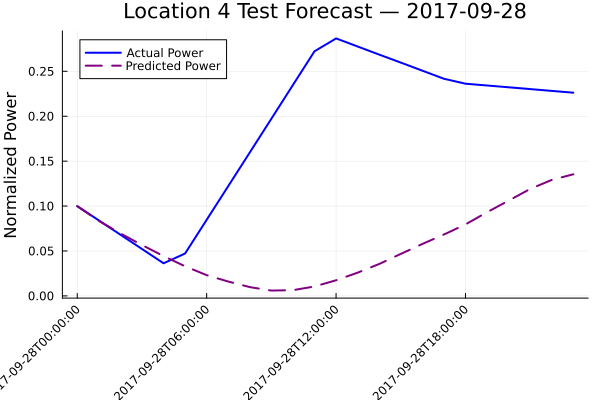

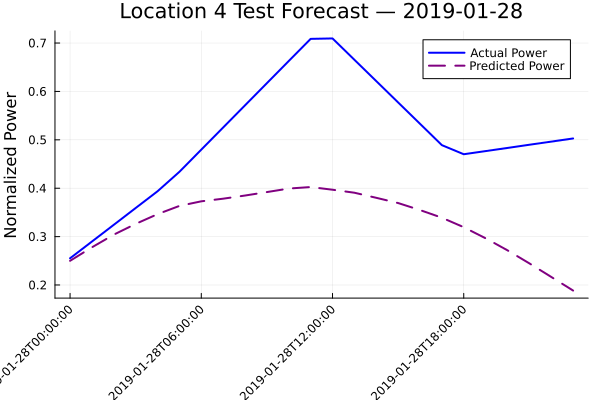

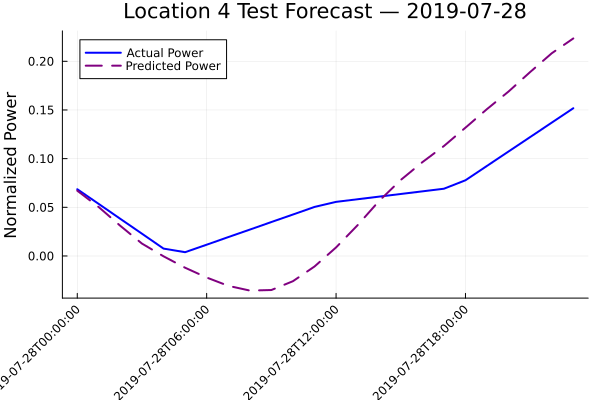

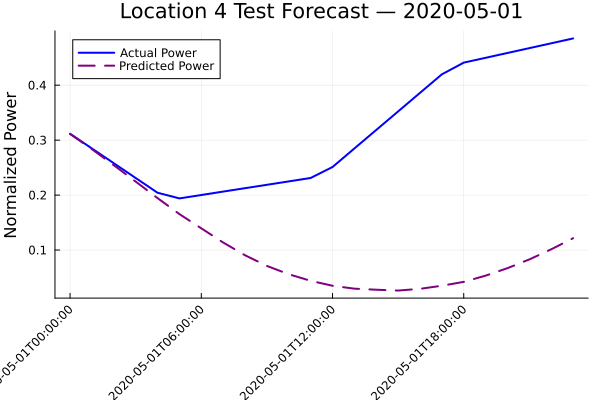

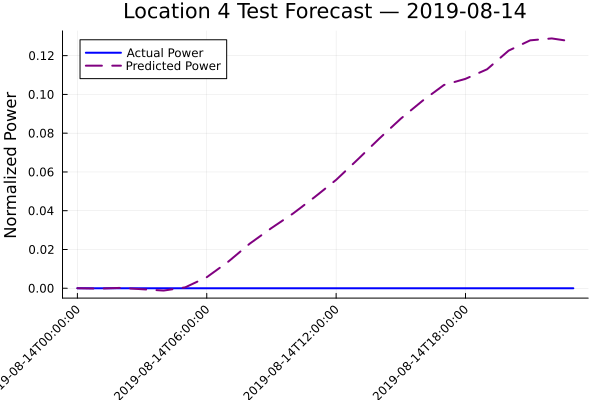

In [3]:
for day in Random.shuffle(test_days)[1:min(5, length(test_days))]
    day_data = filter(row -> Date(row.Time) == day, test_predictions)
    isempty(day_data) && continue

    p = plot(day_data.Time, day_data.ActualPower; label="Actual Power", color=:blue, linewidth=2, xlabel="Time", ylabel="Normalized Power", title="Location 4 Test Forecast — $day", legend=:best, xrotation=45)
    plot!(p, day_data.Time, day_data.PredictedPower; label="Predicted Power", color=:purple, linewidth=2, linestyle=:dash)
    display(p)
end